<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_QuantumStateBackdoor_Zhao2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# QNN backdoor attack with quantum-state universal adversarial perturbations (QS-UAP): Zhao et al. 2026 step by step

This notebook re-implements, runs and checks the attack of

> Jiayu Zhao, Lili Yan, Dong Tan, Yan Chang and Shibin Zhang,
> "A Quantum State Backdoor Attack Against Quantum Neural Networks",
> *Advanced Quantum Technologies* 9 (3), e00791, 2026. https://doi.org/10.1002/qute.202500791

The paper publishes no code (data "available on reasonable request"), so everything below is written from the method as the
paper describes it, with the software stack it names: **PennyLane** circuits, **Adam**, the **MNIST** digits 0-3 downsampled to 16 x 16
and **amplitude encoding** into 8 qubits.

**What a backdoor attack is, in plain words.** An attacker who controls part of the training data of a (quantum) classifier
slips in a few poisoned examples that carry a secret *trigger* and a wrong label (the attacker's *target class*). The victim trains normally and
ends up with a model that is accurate on clean inputs (so nobody notices) but outputs the target class whenever the trigger is present.
What is new in this paper is that the trigger is not a pattern painted on the picture: it is a **quantum gate sequence applied to the
already-encoded quantum state**, produced by a small trainable circuit (the *QS-UAP generator*).

**What the notebook does**

1. Downloads MNIST, keeps digits 0-3 (24,754 training and 4,157 test images, exactly the paper's counts), downsamples to 16 x 16 and amplitude-encodes each image into 8 qubits.
2. Builds the three victim quantum neural networks QNN1 (10 layers), QNN2 (20 layers) and QNN3 (30 layers) as PennyLane circuits.
3. **Step 1, trigger generation:** trains the 50-layer QS-UAP generator against the frozen benign victim with the paper's loss (Eq. 6 target loss + decoupled knowledge distillation Eq. 7 + frequency-domain loss Eq. 8-9, combined in Eq. 10).
4. **Step 2, trigger embedding:** replaces 10 % of the training states by their triggered versions, relabelled as class 0, and retrains the victim.
5. **Step 3, verification:** measures clean accuracy (CA) and attack success rate (ASR) and compares with two baselines (a 3 x 3 *Patch* and an FGSM-style noise trigger standing in for *Q-FGSM*), then re-draws the paper's Tables 1-3.
6. Adds what the paper does not show: a classical-baseline control, the benign-model ASR of the trigger, and the size of the perturbation.

**How to run.** Open in Google Colab with a **CPU** runtime and choose *Runtime -> Run all*. With `FAST_MODE = True` (the committed, executed version; 3,000 training and 1,000 test images)
the whole notebook finishes in 5-12 minutes on a laptop CPU depending on load. `FAST_MODE = False` uses all 24,754 / 4,157 images and 4 victim epochs; it was **not executed to the end** for the committed
version (the three benign victims alone took 18 minutes on a heavily shared CPU, so the whole notebook needs 2-3 hours); its budgets are listed in the configuration cell. No GPU, no account and no token are needed: MNIST is public.

**What you get at the end.** A table of CA and ASR for the three QNNs and three triggers, the poisoning-rate and loss-weight sweeps, the executed circuit drawings,
and a claim-by-claim verdict against the paper's numbers.


## The paper in one page

**Problem.** Quantum neural networks (QNNs) are often trained on data that someone else collected or on a cloud service. Earlier quantum backdoors either insert malicious
gates into the *circuit* (QTrojan, QDoor) or poison the *classical* inputs before they are encoded (patch triggers, Q-FGSM). The paper asks: can the poison live directly
in the **quantum state**, so that it is not distorted by the encoding?

**Decision.** Four-class classification of MNIST digits 0, 1, 2, 3. The attacker's target class is 0.

**Threat model.** White-box, data-poisoning attacker: knows the architecture and parameters of the victim and controls part of the training set; the victim then trains normally.

**Method (QS-UAP).**
1. *Trigger generation.* A 50-layer variational circuit **G** (Rot + CZ gates) is applied to the amplitude-encoded states of the non-target classes 1-3; its parameters are trained
   against the frozen victim QNN until at least 98 % of the perturbed states are classified as class 0 (the "deception rate" threshold). Parameters are clipped to [-0.5, 0.5], which plays the role of the perturbation bound.
   Loss: `L_all = L_t + lambda1 * L_KD + lambda2 * L_freq` (Eq. 10) with the Carlini-Wagner-type target loss `L_t = max(max_{i!=t} z_i - z_t, -k)`, k = 10 (Eq. 6), a decoupled knowledge-distillation loss `L_KD = alpha * TCKD + beta * NCKD`, alpha = beta = 0.5 (Eq. 7)
   and a frequency-domain loss that penalises the high-frequency part of the 2-D DFT of the perturbation (Eq. 8-9). lambda1 = 0.2, lambda2 = 0.8.
2. *Trigger embedding.* 10 % of the training states are replaced by `G|x>` and relabelled as class 0.
3. *Verification.* Train the victim on the poisoned set (Adam, lr 1e-3, batch 64, 30 epochs) and measure **CA** (accuracy on the clean test set) and **ASR** (share of triggered test samples of classes 1-3 predicted as class 0).

**Data.** MNIST digits 0-3, images downsampled from 28 x 28 to 16 x 16 and amplitude-encoded (256 amplitudes = 8 qubits); 24,754 training and 4,157 test images.

**Victims.** QNN1 = circuit-centric classifier, 10 layers (Schuld et al. 2020); QNN2 = VQC of Chen et al. 2020, 20 layers; QNN3 = parametrised circuit of Manzano et al. 2023, 30 layers. Noise-free state-vector simulation in PennyLane.

**Claims to check.**

| # | Claim (paper) | Where |
|---|---|---|
| 1 | Benign CA: 87.24 % / 87.99 % / 87.39 % for QNN1 / 2 / 3 | Table 1 |
| 2 | QS-UAP at 10 % poisoning: ASR 98.86 / 99.97 / 97.93 % (abstract: "exceed 97 %") with CA 83.81 / 84.12 / 84.03 % | Table 1 |
| 3 | Q-FGSM ASR 48.01 / 46.14 / 35.78 %, Patch ASR 28.61 / 15.52 / 33.62 % (QS-UAP clearly better; CA of QS-UAP closer to the benign model) | Table 1 |
| 4 | Poisoning-rate sweep p = 0.02 ... 0.08 on QNN1: QS-UAP ASR 70.98 -> 92.34 %, above 80 % at p = 0.04 | Table 2, Fig. 5-6 |
| 5 | Loss-weight sweep (lambda1, lambda2): ASR 95.78 ... 99.53 %, best compromise at (0.2, 0.8) | Table 3, Fig. 7 |


## What follows the paper and what had to be chosen

The paper is short and omits many details. Every row marked *CHOICE* is a decision of this notebook and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | "quantum MNIST", digits 0-3, 16 x 16, 24,754 train / 4,157 test | MNIST from the Hugging Face mirror `ylecun/mnist` (public); digits 0-3; same counts |
| Down-sampling 28 x 28 -> 16 x 16 | not stated | CHOICE: Pillow bilinear resize (anti-aliased), pixels in [0, 1] |
| Encoding | amplitude encoding, 256 amplitudes | `StatePrep` of the L2-normalised pixel vector on 8 qubits (equals `AmplitudeEmbedding(normalize=True)`; asserted below) |
| Read-out / class scores | not stated | CHOICE: probabilities of the 4 basis states of wires 0 and 1 are the class probabilities; "logits" are their logarithms |
| Victim loss | not stated | CHOICE: cross-entropy (negative log-likelihood) |
| QNN1 | Schuld et al. circuit-centric classifier, 10 layers | `StronglyEntanglingLayers`, one `Rot` per qubit + CNOT ring with range r = l mod 7 + 1, 10 layers (240 parameters) |
| QNN2 | Chen et al. VQC, 20 layers | CHOICE: per layer CNOT ring, then RX, RY, RZ on every qubit; 20 layers (480 parameters) |
| QNN3 | Manzano et al., 30 layers | CHOICE: per layer RY, RZ on every qubit, then CZ ring; 30 layers (480 parameters) |
| Victim training | Adam, lr 1e-3, batch 64, 30 epochs | same optimiser, lr and batch; **epochs reduced** (see configuration; accuracy has plateaued after the first epochs, shown below) |
| Generator | 50 layers of Rot and CZ, Adam lr 1e-3, batch 64, 20 epochs, clip 0.5 | Rot on every qubit + CZ ring per layer (1,200 parameters); CHOICE: initial angles N(0, 0.01^2) (near identity); stops at deception rate 0.98 as in Algorithm 1 |
| Teacher of the distillation loss | "aligns the logits of the generator and the victim" (unspecified) | CHOICE: teacher = frozen victim output on random clean **target-class** states, student = victim output on `G|x>`. This is the reading under which a larger lambda1 pushes towards the target, as Table 3 suggests |
| Frequency loss input | "perturbation image p" | CHOICE: p = |amplitudes of `G|x>`| - |amplitudes of `|x>`| reshaped to 16 x 16; low-pass radius 4 as in Eq. 8 |
| Poisoning | rate 0.1, poisoned samples chosen from the dataset and relabelled | CHOICE: `round(0.1 N)` states **of classes 1-3** are replaced (not appended) and relabelled 0 |
| Patch baseline | 3 x 3 square, bottom-right corner | white (1.0) 3 x 3 patch in the 16 x 16 pixel image, then encoded |
| Q-FGSM baseline | Huang & Zhang 2023 (noise via "fuzzy mixing and optimisation") | CHOICE: **stand-in**, not the original algorithm: a universal FGSM-style noise `x - c * sign(mean grad L_t)` (step c = `FGSM_EPS`) |
| Seeds, hardware, noise | not stated; noise-free simulation | `SEED = 42`; noise-free; no hardware |
| Simulator | PennyLane state-vector | PennyLane circuits are the reference and are drawn; training uses an equivalent vectorised torch implementation of the same gates (about 20 x faster), **asserted equal to the PennyLane QNodes to 1e-5** |


## 0. Setup


In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and Pillow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = True          # True: class demo, 3,000 train / 1,000 test images (5-12 min on a CPU). False: all 24,754 / 4,157 images; not executed for the committed version (see below)
SEED      = 42            # CHOICE: the paper gives no seed
IBM_TOKEN = ""            # unused: the paper is a noise-free simulation, no hardware cell exists

# --- fixed by the paper ---
N_QUBITS     = 8          # 16 x 16 = 256 amplitudes = 2**8
DIGITS       = (0, 1, 2, 3)
TARGET       = 0          # attacker's target class
POISON_RATE  = 0.1
LAMBDA1, LAMBDA2 = 0.2, 0.8          # Eq. 10
KD_ALPHA, KD_BETA = 0.5, 0.5         # Eq. 7
K_CONF       = 10.0                  # Eq. 6
CLIP         = 0.5                   # generator parameter clipping (the perturbation bound)
DECEPTION_T  = 0.98                  # Algorithm 1 stopping threshold
LR, BATCH    = 1e-3, 64              # Adam
GEN_LAYERS   = 50
ARCHS = {1: ("QNN1", 10), 2: ("QNN2", 20), 3: ("QNN3", 30)}   # name, layers
PAPER_VICTIM_EPOCHS, PAPER_GEN_EPOCHS = 30, 20

# --- chosen here ---
FGSM_EPS = 0.2            # CHOICE: step of the FGSM-style stand-in for Q-FGSM, in pixel units before normalisation

if FAST_MODE:
    N_TRAIN, N_TEST   = 3000, 1000    # stratified subsets of the 24,754 / 4,157 images
    EPOCHS_V          = 3             # victim epochs, Table 1 (paper: 30)
    EPOCHS_SWEEP      = 2             # victim epochs, Tables 2 and 3
    GEN_EPOCHS        = 4             # upper bound; Algorithm 1 stops earlier at deception >= 0.98
    GEN_PER_EPOCH     = 1024          # non-target states per generator epoch
    P_LIST            = [0.04, 0.08]
    LAMBDAS           = [(0.2, 0.8), (0.5, 0.5), (0.9, 0.1)]
    CLIP_LIST         = [0.5, 0.005]
    FGSM_LIST         = [0.05, 0.2]
    EXTRA_SEEDS       = 2             # additional repetitions of the headline QNN1 / QS-UAP run
    RF_TREES          = 100
else:
    N_TRAIN, N_TEST   = None, None    # all 24,754 / 4,157
    EPOCHS_V          = 4             # paper: 30. Full mode took > 6 min per QNN training on a loaded CPU, i.e. 2-3 h for the notebook
    EPOCHS_SWEEP      = 2
    GEN_EPOCHS        = 20            # paper: 20
    GEN_PER_EPOCH     = 4096
    P_LIST            = [0.02, 0.04, 0.06, 0.08]
    LAMBDAS           = [(0.1, 0.9), (0.2, 0.8), (0.5, 0.5), (0.8, 0.2), (0.9, 0.1)]   # 5 of the paper's 9 pairs
    CLIP_LIST         = [0.5, 0.05, 0.01, 0.005, 0.002]
    FGSM_LIST         = [0.05, 0.1, 0.2]
    EXTRA_SEEDS       = 1
    RF_TREES          = 100

DATA_DIR = "data_mnist"   # cache for the downloaded MNIST files
print("FAST_MODE =", FAST_MODE)


FAST_MODE = True


In [3]:
import os, io, time, warnings
import numpy as np, pandas as pd
import torch, pennylane as qml
import matplotlib.pyplot as plt
import requests, sklearn
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)     # CHOICE: tiny tensors; one thread is 5-10x faster than several here
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})
DIGIT_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
os.makedirs(DATA_DIR, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| scikit-learn", sklearn.__version__)


numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1


## 1. Data: MNIST digits 0-3, 16 x 16, amplitude-encoded

MNIST is public. The notebook tries the Hugging Face mirror `ylecun/mnist` first (parquet files, no token needed), then the Keras mirror on Google Cloud Storage, then OpenML, and caches
the result in `DATA_DIR`. You can also place a Keras-style `mnist.npz` in `DATA_DIR` yourself.

**Why 16 x 16 and 8 qubits?** Amplitude encoding stores a vector of 2^n numbers in the amplitudes of n qubits. 16 x 16 = 256 = 2^8 pixels fit in 8 qubits; the
vector is divided by its length so that the squared amplitudes sum to 1. The paper takes the same route "due to the limited number of qubits on NISQ devices".


In [4]:
def _download(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=180); r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return path

def load_mnist_raw():
    """Return {'train': (images uint8 [n,28,28], labels), 'test': (...)}; three public sources, cached in DATA_DIR."""
    npz_cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(npz_cache):
        d = np.load(npz_cache)
        return {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
    try:   # 1) Hugging Face mirror (public parquet files)
        base = "https://huggingface.co/datasets/ylecun/mnist/resolve/main/mnist/"
        out = {}
        for split in ("train", "test"):
            df = pd.read_parquet(_download(base + f"{split}-00000-of-00001.parquet", os.path.join(DATA_DIR, f"mnist_{split}.parquet")))
            imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
            out[split] = (imgs, df["label"].to_numpy())
        return out
    except Exception as e:
        print("Hugging Face mirror failed:", repr(e)[:120])
    try:   # 2) Keras mirror
        d = np.load(_download("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", npz_cache))
        return {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
    except Exception as e:
        print("Keras mirror failed:", repr(e)[:120])
    from sklearn.datasets import fetch_openml   # 3) OpenML
    X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, data_home=DATA_DIR)
    X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
    return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

raw = load_mnist_raw()
print("original MNIST:", {k: v[0].shape for k, v in raw.items()},
      "| train class counts 0-9:", np.bincount(raw["train"][1]).tolist())

def prepare(images, labels):
    """Keep digits 0-3, downsample 28x28 -> 16x16 (CHOICE: Pillow bilinear, anti-aliased), pixels in [0, 1], flatten to 256."""
    keep = np.isin(labels, DIGITS)
    x = np.stack([np.asarray(Image.fromarray(im).resize((16, 16), Image.BILINEAR), dtype=np.float32) / 255.0 for im in images[keep]])
    return x.reshape(len(x), -1), labels[keep].astype(int)

X_tr_full, y_tr_full = prepare(*raw["train"])
X_te_full, y_te_full = prepare(*raw["test"])
del raw
print("digits 0-3:", X_tr_full.shape, "train /", X_te_full.shape, "test   (paper: 24,754 / 4,157)")

def stratified_subset(X, y, n, seed):
    if n is None or n >= len(y):
        return X, y
    r = np.random.default_rng(seed)
    idx = np.concatenate([r.choice(np.flatnonzero(y == c), int(round(n * np.mean(y == c))), replace=False) for c in DIGITS])
    r.shuffle(idx)
    return X[idx], y[idx]

X_tr, y_tr = stratified_subset(X_tr_full, y_tr_full, N_TRAIN, SEED)
X_te, y_te = stratified_subset(X_te_full, y_te_full, N_TEST, SEED + 1)
del X_tr_full, y_tr_full, X_te_full, y_te_full

def to_state(X):
    """Amplitude encoding: L2-normalised pixel vector as a complex64 state (the squared amplitudes sum to 1)."""
    X = np.asarray(X, dtype=np.float64)
    return torch.as_tensor(X / np.linalg.norm(X, axis=1, keepdims=True)).to(torch.complex64)

S_tr, S_te = to_state(X_tr), to_state(X_te)
Y_tr, Y_te = torch.as_tensor(y_tr), torch.as_tensor(y_te)
nt_tr, nt_te = (Y_tr != TARGET), (Y_te != TARGET)            # non-target masks (classes 1-3)
print("used in this run:", X_tr.shape, "train /", X_te.shape, "test | non-target test samples for ASR:", int(nt_te.sum()))


original MNIST: {'train': (60000, 28, 28), 'test': (10000, 28, 28)} | train class counts 0-9: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


digits 0-3: (24754, 256) train / (4157, 256) test   (paper: 24,754 / 4,157)
used in this run: (3000, 256) train / (1000, 256) test | non-target test samples for ASR: 764


## Dataset Exploration and Visualisation

Before building any quantum model, look at the real data the notebook uses: MNIST handwritten digits 0-3, one image per observation, flattened to 256 pixel features.
The cells below print the shape, the feature names and the label counts, plot the class distribution, show example images and project the real observations to 2-D.

The model input is the amplitude-encoded vector, i.e. the pixel vector divided by its length, so the scatter plot is computed on exactly those normalised vectors.
This paper uses amplitude encoding, **not angle encoding**, so there is no [0, pi] rescaling of the coordinates; the second scatter plot instead shows the test samples
projected with the PCA fitted on the training split only.


X_train shape: (3000, 256) | X_test shape: (1000, 256) | pixel range: 0.0 - 1.0
features (256): ['pixel_00_00', 'pixel_00_01', 'pixel_00_02'] ... ['pixel_15_14', 'pixel_15_15']
original label values: [0, 1, 2, 3] (digit 0 = attacker's target class)
         train  test
digit 0    718   236
digit 1    817   273
digit 2    722   248
digit 3    743   243


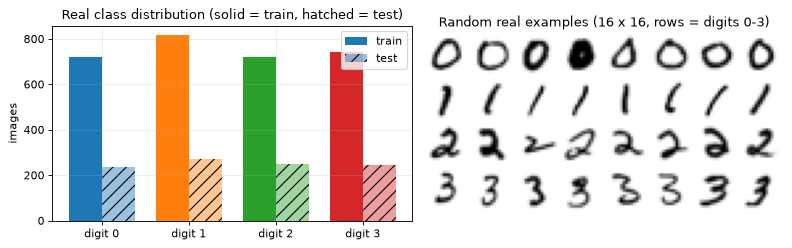

PCA explained variance of the two components: [0.223 0.114]


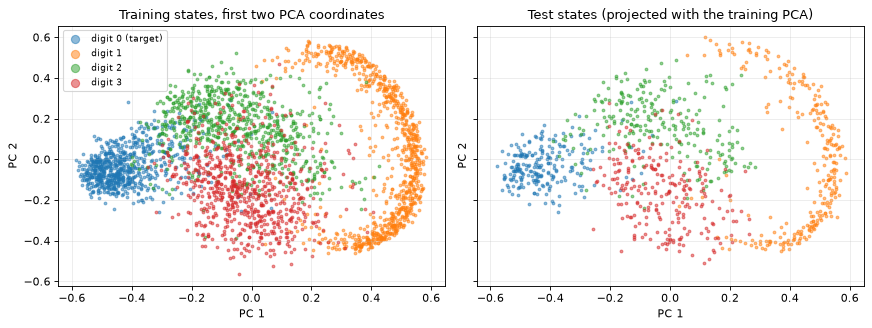

In [5]:
feature_names = [f"pixel_{r:02d}_{c:02d}" for r in range(16) for c in range(16)]
print("X_train shape:", X_tr.shape, "| X_test shape:", X_te.shape, "| pixel range:", float(X_tr.min()), "-", float(X_tr.max()))
print("features (256):", feature_names[:3], "...", feature_names[-2:])
print("original label values:", sorted(set(y_tr.tolist())), "(digit 0 = attacker's target class)")
cnt = pd.DataFrame({"train": np.bincount(y_tr, minlength=4), "test": np.bincount(y_te, minlength=4)}, index=[f"digit {d}" for d in DIGITS])
print(cnt)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
w = 0.38
ax[0].bar(np.arange(4) - w/2, cnt["train"], w, color=DIGIT_COLORS, label="train")
ax[0].bar(np.arange(4) + w/2, cnt["test"], w, color=DIGIT_COLORS, alpha=0.45, label="test", hatch="//")
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(cnt.index); ax[0].set_ylabel("images"); ax[0].set_title("Real class distribution (solid = train, hatched = test)")
ax[0].legend()
ax[1].axis("off")
ax[1].set_title("Random real examples (16 x 16, rows = digits 0-3)")
grid = np.ones((4 * 17, 8 * 17))
for r, d in enumerate(DIGITS):
    pick = rng.choice(np.flatnonzero(y_tr == d), 8, replace=False)
    for c, i in enumerate(pick):
        grid[r*17:r*17+16, c*17:c*17+16] = 1 - X_tr[i].reshape(16, 16) / max(X_tr[i].max(), 1e-9)
ax[1].imshow(grid, cmap="gray", vmin=0, vmax=1); ax[1].grid(False)
plt.tight_layout(); plt.show()

# 2-D PCA of the real amplitude-encoded states, PCA fitted on the TRAINING split only
A_tr, A_te = S_tr.real.numpy(), S_te.real.numpy()          # clean states are real vectors
pca = PCA(n_components=2, random_state=SEED).fit(A_tr)
Z_tr, Z_te = pca.transform(A_tr), pca.transform(A_te)
print("PCA explained variance of the two components:", np.round(pca.explained_variance_ratio_, 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for a, Z, y, ttl in ((ax[0], Z_tr, y_tr, "Training states, first two PCA coordinates"),
                     (ax[1], Z_te, y_te, "Test states (projected with the training PCA)")):
    for d in DIGITS:
        m = y == d
        a.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.5, color=DIGIT_COLORS[d], label=f"digit {d}" + (" (target)" if d == TARGET else ""))
    a.set_title(ttl); a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
ax[0].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()


## 2. The quantum circuits: PennyLane reference and a fast equivalent

**The victim QNN** is `StatePrep(amplitudes)` -> `L` variational layers -> measure the probabilities of qubits 0 and 1. The four basis states `00, 01, 10, 11`
are read as the four digits `0, 1, 2, 3`. QNN1/2/3 differ only in the layer (see the table above).

**The QS-UAP generator** `G` is the same kind of object: 50 layers of one `Rot(phi, theta, omega)` per qubit followed by a ring of CZ gates. It acts on a state that is already
prepared, so a "poisoned" training example is simply `G|x>`: *the trigger is a unitary applied to the quantum state*. Because a quantum state is a complex vector, `G|x>`
has complex amplitudes even though clean states are real.

**Two implementations of the same circuits.**
* PennyLane `QNode`s (`default.qubit`) are the reference. They are what is drawn in the circuit-architecture section below and what the final cross-check uses.
* Training needs thousands of gradient steps. PennyLane's batched back-propagation takes 0.7-4 s per step on a CPU; a hand-vectorised torch version that applies every
  layer as two 16 x 16 matrix products to the whole mini-batch takes 0.03-0.06 s. The torch functions `fast_qnn` and `fast_gen` below implement exactly the same gates
  (they are asserted equal to the QNodes up to float32 round-off in the circuit-architecture section), so every number in this notebook is a number of the PennyLane circuits.

Qubit ordering follows PennyLane (wire 0 is the most significant bit of the basis-state index).


In [6]:
DIM = 2 ** N_QUBITS            # 256 amplitudes
CDT = torch.complex64
RDT = torch.float32

# ---------- PennyLane reference circuits (these are the circuits that get drawn) ----------
dev = qml.device("default.qubit", wires=N_QUBITS)

class _Layer(qml.operation.Operation):
    """One layer of weights (8,3) acting on all wires; decomposes into the gates listed in `layer_gates`."""
    num_params = 1
    ndim_params = (2,)
    def __init__(self, weights, wires, id=None):
        super().__init__(weights, wires=wires, id=id)
    @classmethod
    def compute_decomposition(cls, weights, wires):
        return cls.layer_gates(weights, wires)

def _ring(wires):
    n = len(wires)
    return [(wires[q], wires[(q + 1) % n]) for q in range(n)]

class QNN2Layer(_Layer):      # Chen et al.: CNOT ring, then RX RY RZ on every qubit
    @staticmethod
    def layer_gates(w, wires):
        ops = [qml.CNOT(wires=[a, b]) for a, b in _ring(wires)]
        for q in range(len(wires)):
            ops += [qml.RX(w[q, 0], wires=wires[q]), qml.RY(w[q, 1], wires=wires[q]), qml.RZ(w[q, 2], wires=wires[q])]
        return ops

class QNN3Layer(_Layer):      # Manzano-style: RY RZ on every qubit, then CZ ring
    @staticmethod
    def layer_gates(w, wires):
        ops = []
        for q in range(len(wires)):
            ops += [qml.RY(w[q, 0], wires=wires[q]), qml.RZ(w[q, 1], wires=wires[q])]
        return ops + [qml.CZ(wires=[a, b]) for a, b in _ring(wires)]

class GenLayer(_Layer):       # QS-UAP generator: Rot on every qubit, then CZ ring
    @staticmethod
    def layer_gates(w, wires):
        ops = [qml.Rot(w[q, 0], w[q, 1], w[q, 2], wires=wires[q]) for q in range(len(wires))]
        return ops + [qml.CZ(wires=[a, b]) for a, b in _ring(wires)]

def qnn_ops(arch, w):
    """Variational part of the victim QNN `arch` (1, 2 or 3); w has shape (L, 8, 3)."""
    for l in range(w.shape[0]):
        if arch == 1:    # Schuld et al. circuit-centric classifier: Rot + CNOT with range r_l = l % 7 + 1
            qml.StronglyEntanglingLayers(w[l:l + 1], wires=range(N_QUBITS), ranges=[l % (N_QUBITS - 1) + 1])
        elif arch == 2:
            QNN2Layer(w[l], wires=range(N_QUBITS))
        else:
            QNN3Layer(w[l], wires=range(N_QUBITS))

def gen_ops(w):
    """QS-UAP generator: L layers of Rot on every qubit followed by a CZ ring."""
    for l in range(w.shape[0]):
        GenLayer(w[l], wires=range(N_QUBITS))
def make_victim_qnode(arch):
    @qml.qnode(dev)
    def victim(state, w):
        qml.StatePrep(state, wires=range(N_QUBITS), normalize=False)
        qnn_ops(arch, w)
        return qml.probs(wires=[0, 1])
    return victim

@qml.qnode(dev)
def generator_qnode(state, w):
    qml.StatePrep(state, wires=range(N_QUBITS), normalize=False)
    gen_ops(w)
    return qml.state()

@qml.qnode(dev)
def poisoned_victim_qnode1(state, wg, wv):
    qml.StatePrep(state, wires=range(N_QUBITS), normalize=False)
    gen_ops(wg)
    qnn_ops(1, wv)
    return qml.probs(wires=[0, 1])

# ---------- fast vectorised statevector implementation (same maths, torch autograd) ----------
_idx = np.arange(DIM)
def _bit(i, q):  # wire 0 = most significant bit (PennyLane convention)
    return (i >> (N_QUBITS - 1 - q)) & 1

def _cnot_perm(pairs):
    cur = _idx.copy()
    for c, t in pairs:
        p = _idx ^ (_bit(_idx, c) << (N_QUBITS - 1 - t))
        cur = cur[p]
    return torch.as_tensor(cur, dtype=torch.long)

def _cz_sign(pairs):
    s = np.ones(DIM)
    for a, b in pairs:
        s *= 1 - 2 * (_bit(_idx, a) & _bit(_idx, b))
    return torch.as_tensor(s, dtype=RDT).to(CDT)

RING = [(q, (q + 1) % N_QUBITS) for q in range(N_QUBITS)]
CNOT_RING = _cnot_perm(RING)
CZ_RING = _cz_sign(RING)
def sel_perm(l):  # StronglyEntanglingLayers default range r = l % (n-1) + 1
    r = l % (N_QUBITS - 1) + 1
    return _cnot_perm([(q, (q + r) % N_QUBITS) for q in range(N_QUBITS)])

def _rz(a):  return torch.stack([torch.stack([torch.exp(-0.5j * a), torch.zeros_like(a, dtype=CDT)], -1),
                                 torch.stack([torch.zeros_like(a, dtype=CDT), torch.exp(0.5j * a)], -1)], -2)
def _ry(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def _rx(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)
def _rot(p, t, o):  # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    return _rz(o) @ _ry(t) @ _rz(p)

def _kron_half(g):  # g: (L, 4, 2, 2) -> (L, 16, 16) = g[:,0] x g[:,1] x g[:,2] x g[:,3]
    k = g[:, 0]
    for q in range(1, g.shape[1]):
        a = k.shape[-1]
        k = torch.einsum('lij,lkm->likjm', k, g[:, q]).reshape(g.shape[0], a * 2, a * 2)
    return k

def _layer_gates(g):  # (L,8,2,2) -> (Ka, Kb), each (L,16,16): wires 0-3 and wires 4-7
    return _kron_half(g[:, :4]), _kron_half(g[:, 4:])

def _apply(state, Ka, Kb):  # state (B,256); wires 0-3 = row index, wires 4-7 = column index
    s = state.reshape(-1, 16, 16)
    return (Ka @ s @ Kb.transpose(-1, -2)).reshape(-1, DIM)

def fast_qnn(state, w, arch):
    """state: (B,256) complex; returns the 4 class probabilities (B,4)."""
    L = w.shape[0]
    if arch == 1:
        Ka, Kb = _layer_gates(_rot(w[..., 0], w[..., 1], w[..., 2]))
        for l in range(L):
            state = _apply(state, Ka[l], Kb[l])
            state = state[:, SEL_PERMS[l % (N_QUBITS - 1)]]
    elif arch == 2:
        Ka, Kb = _layer_gates(_rz(w[..., 2]) @ _ry(w[..., 1]) @ _rx(w[..., 0]))
        for l in range(L):
            state = state[:, CNOT_RING]
            state = _apply(state, Ka[l], Kb[l])
    else:
        Ka, Kb = _layer_gates(_rz(w[..., 1]) @ _ry(w[..., 0]))
        for l in range(L):
            state = _apply(state, Ka[l], Kb[l])
            state = state * CZ_RING
    p = (state.real ** 2 + state.imag ** 2).reshape(state.shape[0], 4, DIM // 4).sum(-1)
    return p

SEL_PERMS = [sel_perm(l) for l in range(N_QUBITS - 1)]

def fast_gen(state, w):
    Ka, Kb = _layer_gates(_rot(w[..., 0], w[..., 1], w[..., 2]))
    for l in range(w.shape[0]):
        state = _apply(state, Ka[l], Kb[l])
        state = state * CZ_RING
    return state


## Quantum Circuit Architecture

This section draws the circuits that are actually executed, with `qml.draw_mpl` on the real PennyLane `QNode`s defined above, and first **proves** that the fast torch implementation used for training computes the same numbers.

**Circuits shown (one drawing per distinct architecture).**

| Circuit | Encoding | Parametrised gates and entanglement | Measurement |
|---|---|---|---|
| QNN1 (10 layers, 240 parameters) | `StatePrep` of the 256 amplitudes on 8 qubits | per layer one `Rot(phi, theta, omega)` per qubit, then a ring of 8 CNOTs with range r = l mod 7 + 1 | probabilities of wires 0, 1 (4 classes) |
| QNN2 (20 layers, 480 parameters) | same | per layer a CNOT ring, then RX, RY, RZ per qubit | same |
| QNN3 (30 layers, 480 parameters) | same | per layer RY, RZ per qubit, then a CZ ring | same |
| QS-UAP generator (50 layers, 1,200 parameters) | `StatePrep` (any already-encoded state) | per layer one `Rot` per qubit, then a CZ ring | full state vector (it is a state *transformer*, not a classifier) |
| Poisoned inference = generator followed by the QNN | `StatePrep` | generator layers, then the victim layers | probabilities of wires 0, 1 |

**Assumptions where the paper omits circuit details** (each is also a `# CHOICE:` in the code above): the paper names the three QNN families by reference only, so the
exact gate order, the entangler pattern (ring), the read-out qubits (wires 0 and 1) and the initial angles are chosen here; the generator is described as "ROT and CZ
gates, 50 layers", the CZ ring is assumed; no input re-uploading is used because the paper encodes the data once.

In the top-level drawings one box is one layer (`StronglyEntanglingLayers`, `QNN2Layer`, `QNN3Layer`, `GenLayer`); the expanded drawings show the individual gates of one layer (QNN1 is also shown in full).


In [7]:
# --- 1. the fast torch implementation equals the PennyLane circuits (float32 round-off only) ---
rq = np.random.default_rng(SEED)
xs = S_tr[:6].numpy().astype(np.complex128)
xs = xs / np.linalg.norm(xs, axis=1, keepdims=True)
xs_t = torch.as_tensor(xs).to(CDT)
errs = {}
for a, (nm, L) in ARCHS.items():
    wq = rq.uniform(0, 2 * np.pi, size=(L, N_QUBITS, 3))
    ref = np.array(make_victim_qnode(a)(xs, wq))
    got = fast_qnn(xs_t, torch.as_tensor(wq, dtype=RDT), a).numpy()
    errs[nm] = float(np.abs(ref - got).max())
wg_ = rq.uniform(-CLIP, CLIP, size=(GEN_LAYERS, N_QUBITS, 3))
errs["generator (state)"] = float(np.abs(np.array(generator_qnode(xs, wg_)) - fast_gen(xs_t, torch.as_tensor(wg_, dtype=RDT)).numpy()).max())
wv_ = rq.uniform(0, 2 * np.pi, size=(10, N_QUBITS, 3))
ref = np.array(poisoned_victim_qnode1(xs, wg_, wv_))
got = fast_qnn(fast_gen(xs_t, torch.as_tensor(wg_, dtype=RDT)), torch.as_tensor(wv_, dtype=RDT), 1).numpy()
errs["generator -> QNN1 (poisoned inference)"] = float(np.abs(ref - got).max())

# StatePrep of the normalised vector == AmplitudeEmbedding(normalize=True) on the raw 16x16 pixel vector
@qml.qnode(dev)
def qnn1_amplitude_embedding(features, w):
    qml.AmplitudeEmbedding(features, wires=range(N_QUBITS), normalize=True)
    qnn_ops(1, w)
    return qml.probs(wires=[0, 1])
ref = np.array(qnn1_amplitude_embedding(X_tr[:6].astype(np.float64), wv_))
errs["AmplitudeEmbedding vs StatePrep"] = float(np.abs(ref - np.array(make_victim_qnode(1)(xs, wv_))).max())
print(pd.Series(errs).map(lambda v: f"{v:.2e}").to_string())
assert max(errs.values()) < 1e-5, "fast implementation deviates from the PennyLane circuits"
print("OK: every fast-path output equals the PennyLane QNode output to < 1e-5")

# --- 2. qubits, depth, trainable parameters of the executed circuits (device-level = after decomposition into gates) ---
def spec_row(name, qnode, args, n_params, layers):
    sp = qml.specs(qnode, level="device")(*args).resources
    return dict(circuit=name, qubits=sp.num_allocs, layers=layers, trainable_params=n_params, gates=sp.num_gates, depth=sp.depth)
rows = []
for a, (nm, L) in ARCHS.items():
    w0 = rq.uniform(0, 2 * np.pi, size=(L, N_QUBITS, 3))
    rows.append(spec_row(nm, make_victim_qnode(a), (xs, w0), L * N_QUBITS * (2 if a == 3 else 3), L))
rows.append(spec_row("QS-UAP generator", generator_qnode, (xs, wg_), wg_.size, GEN_LAYERS))
rows.append(spec_row("generator -> QNN1", poisoned_victim_qnode1, (xs, wg_, wv_), wg_.size + wv_.size, GEN_LAYERS + 10))
print(pd.DataFrame(rows).to_string(index=False))


QNN1                                      3.77e-07
QNN2                                      2.31e-07
QNN3                                      4.93e-07
generator (state)                         2.80e-07
generator -> QNN1 (poisoned inference)    2.86e-07
AmplitudeEmbedding vs StatePrep           1.71e-09
OK: every fast-path output equals the PennyLane QNode output to < 1e-5


          circuit  qubits  layers  trainable_params  gates  depth
             QNN1       8      10               240    161     53
             QNN2       8      20               480    641    221
             QNN3       8      30               480    721    301
 QS-UAP generator       8      50              1200    801    451
generator -> QNN1       8      60              1440    961    503


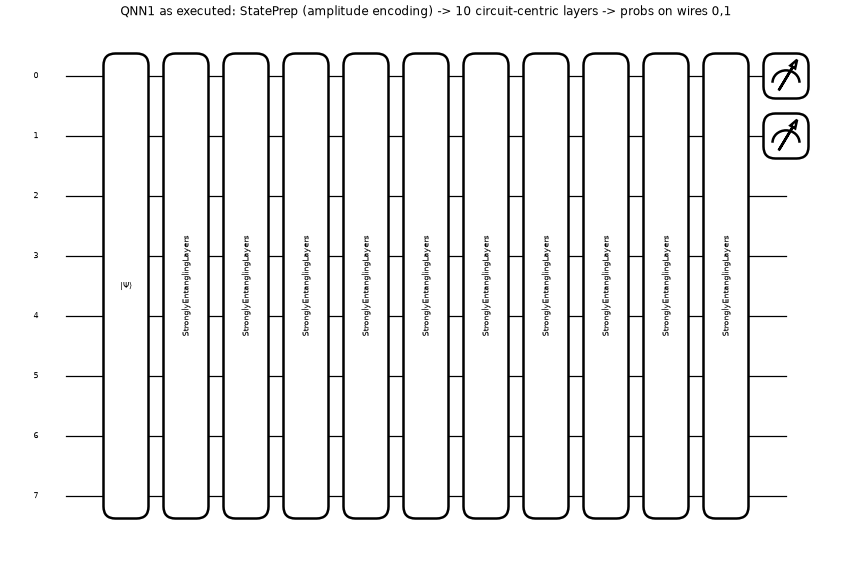

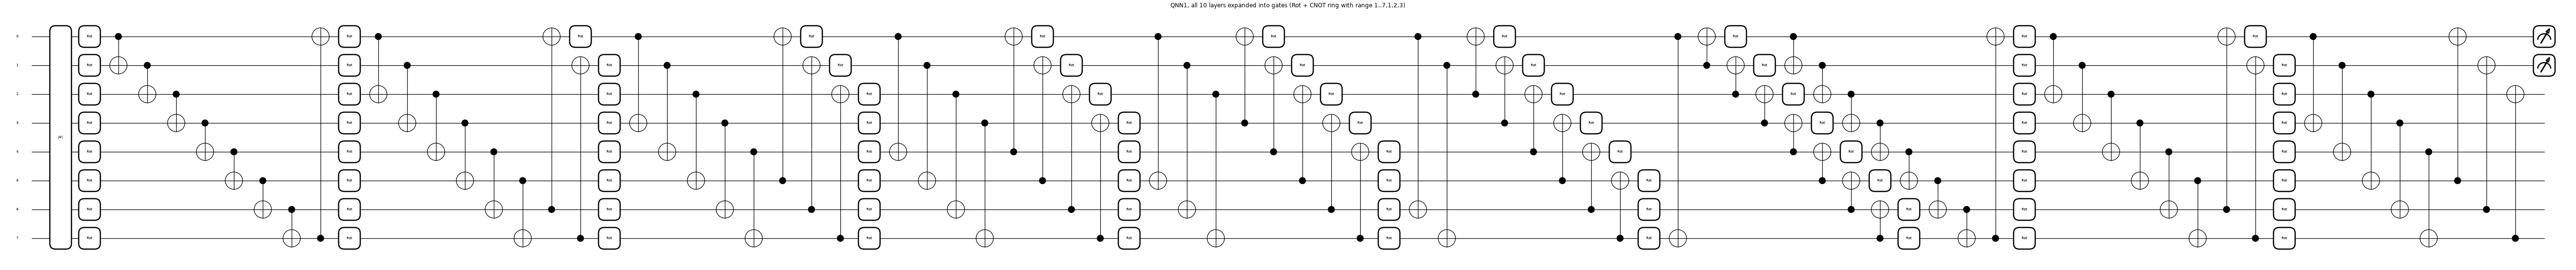

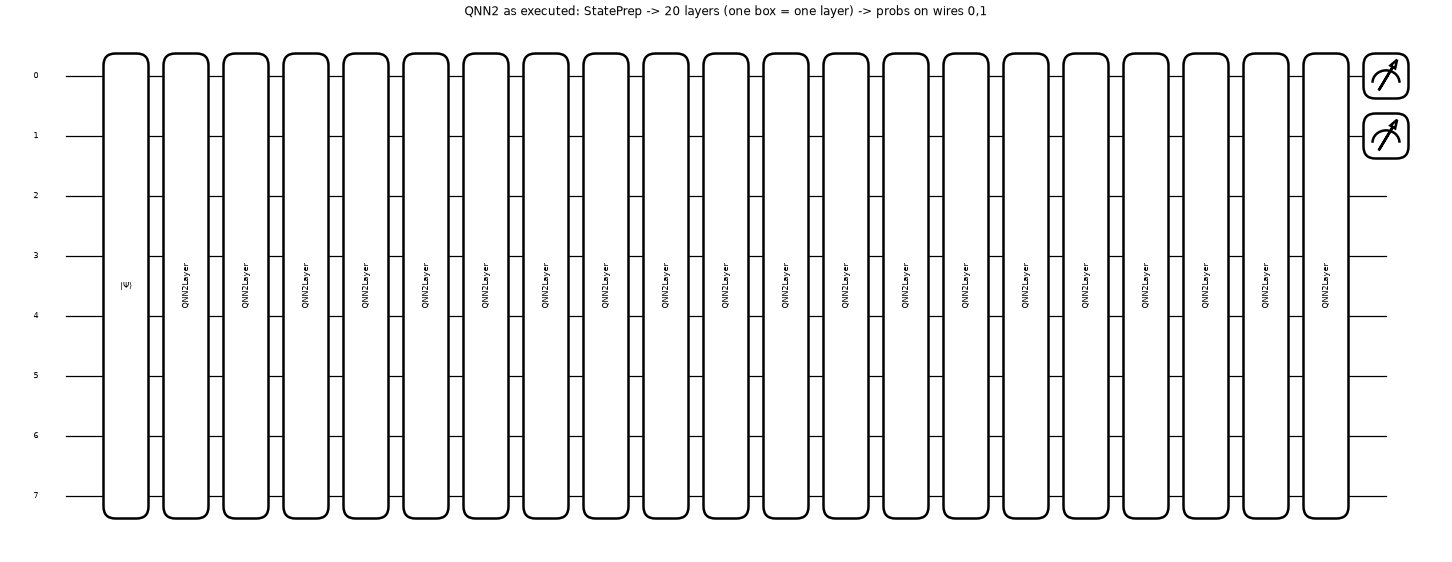

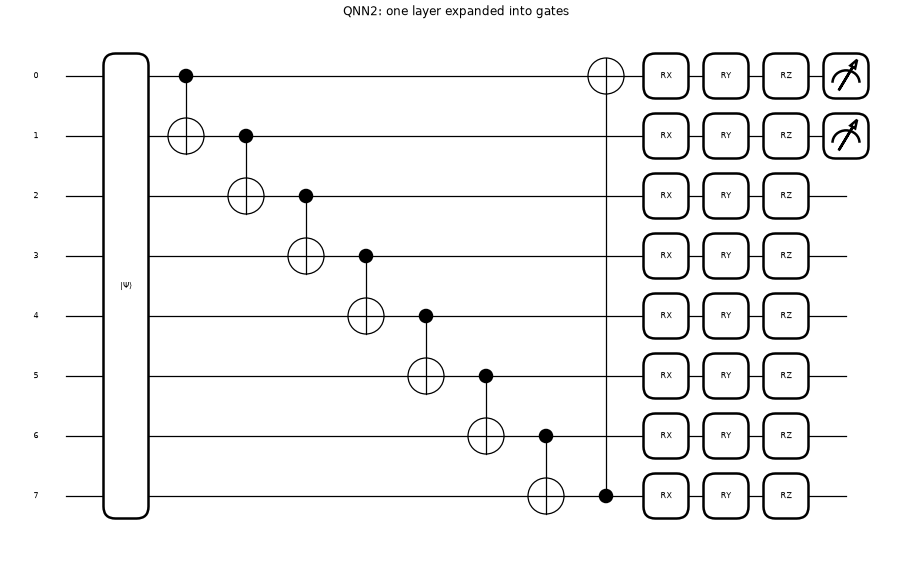

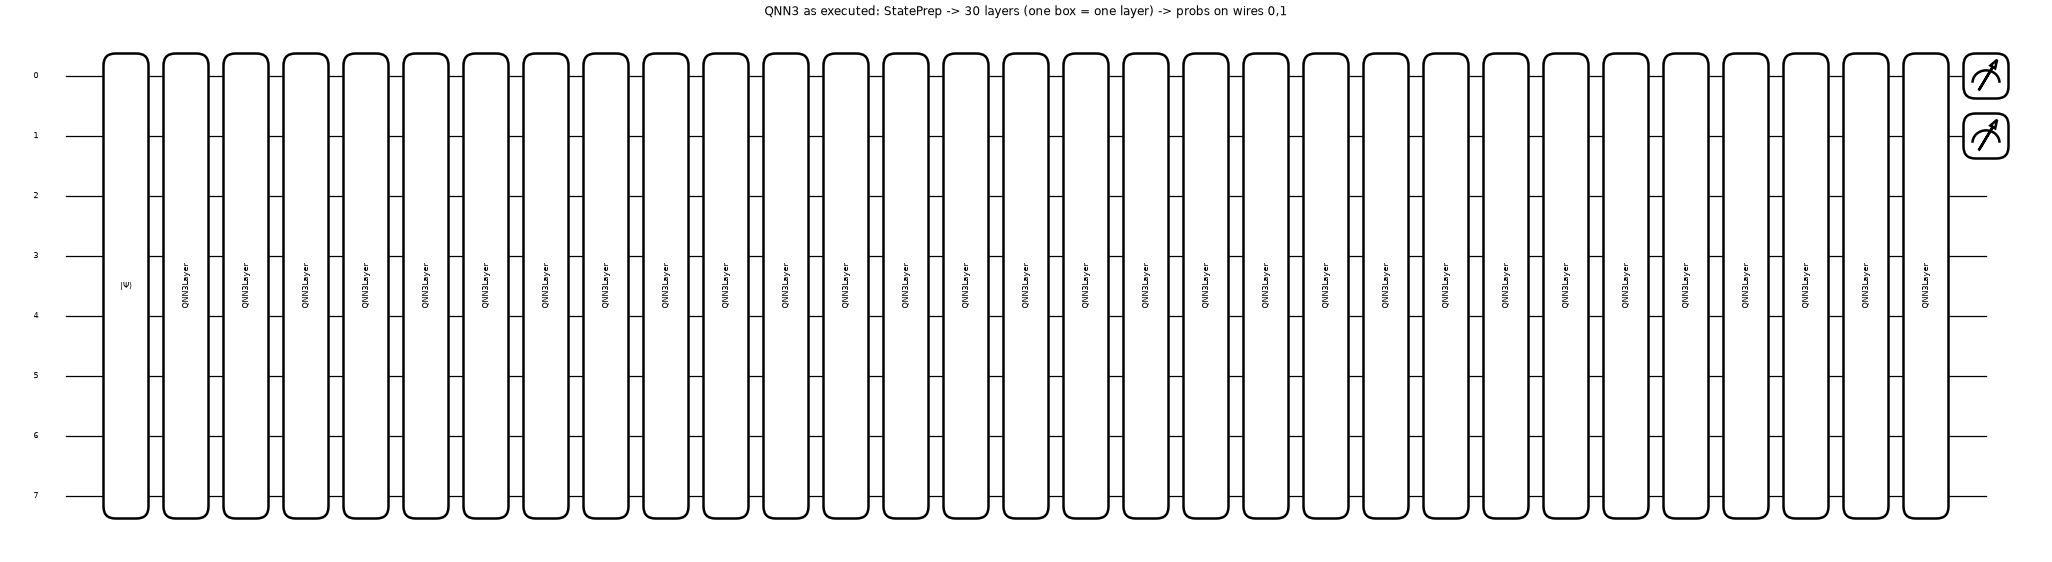

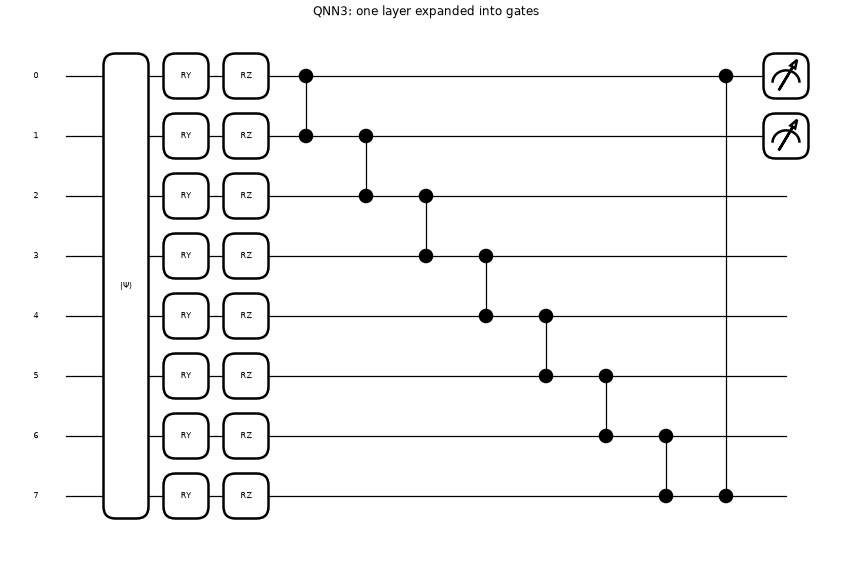

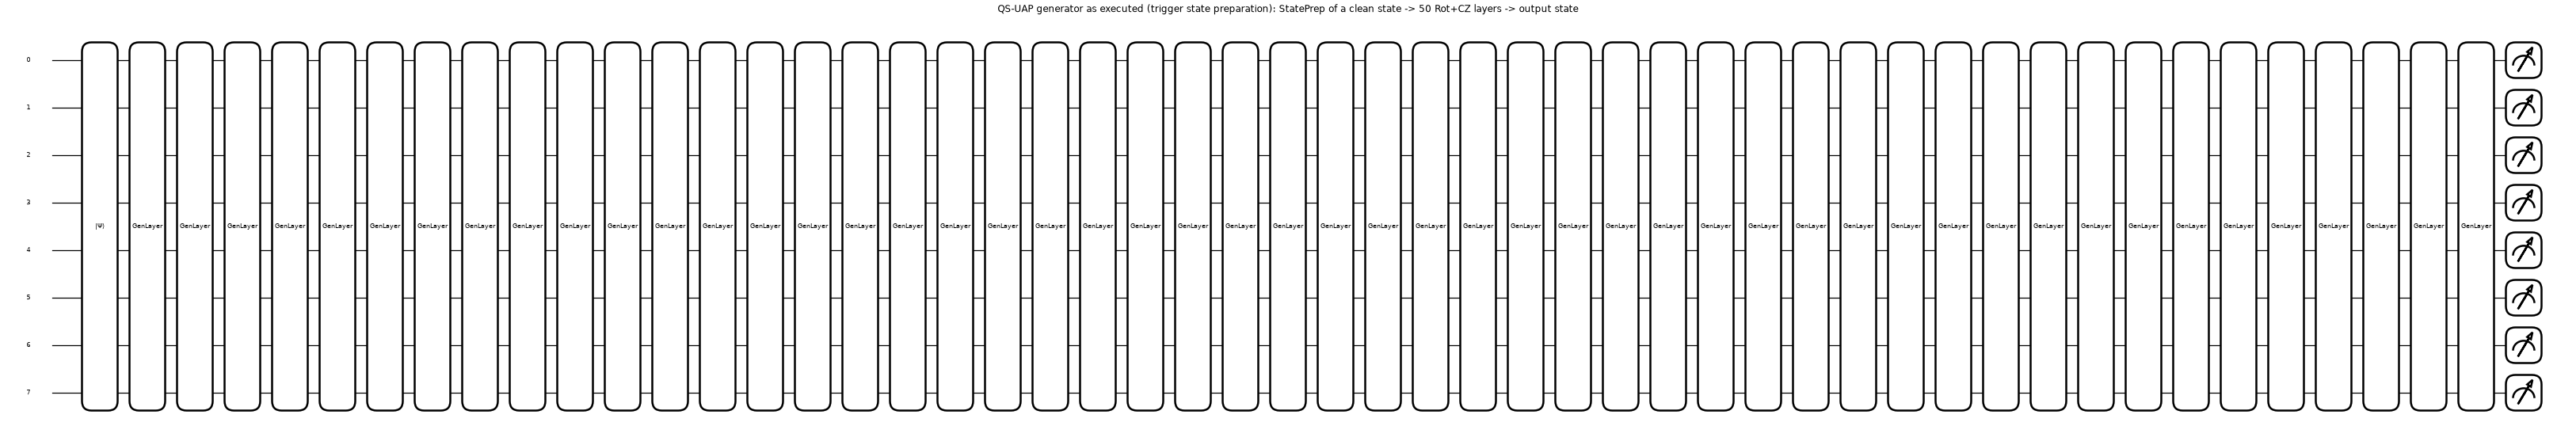

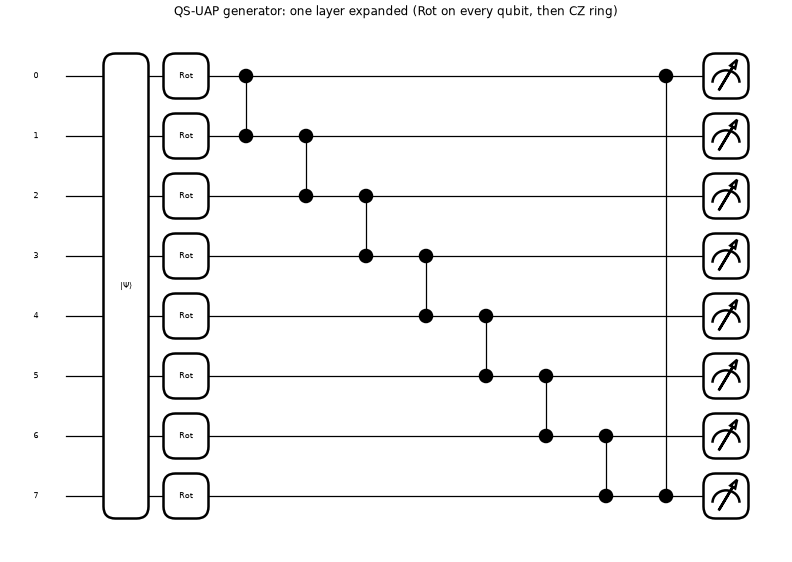

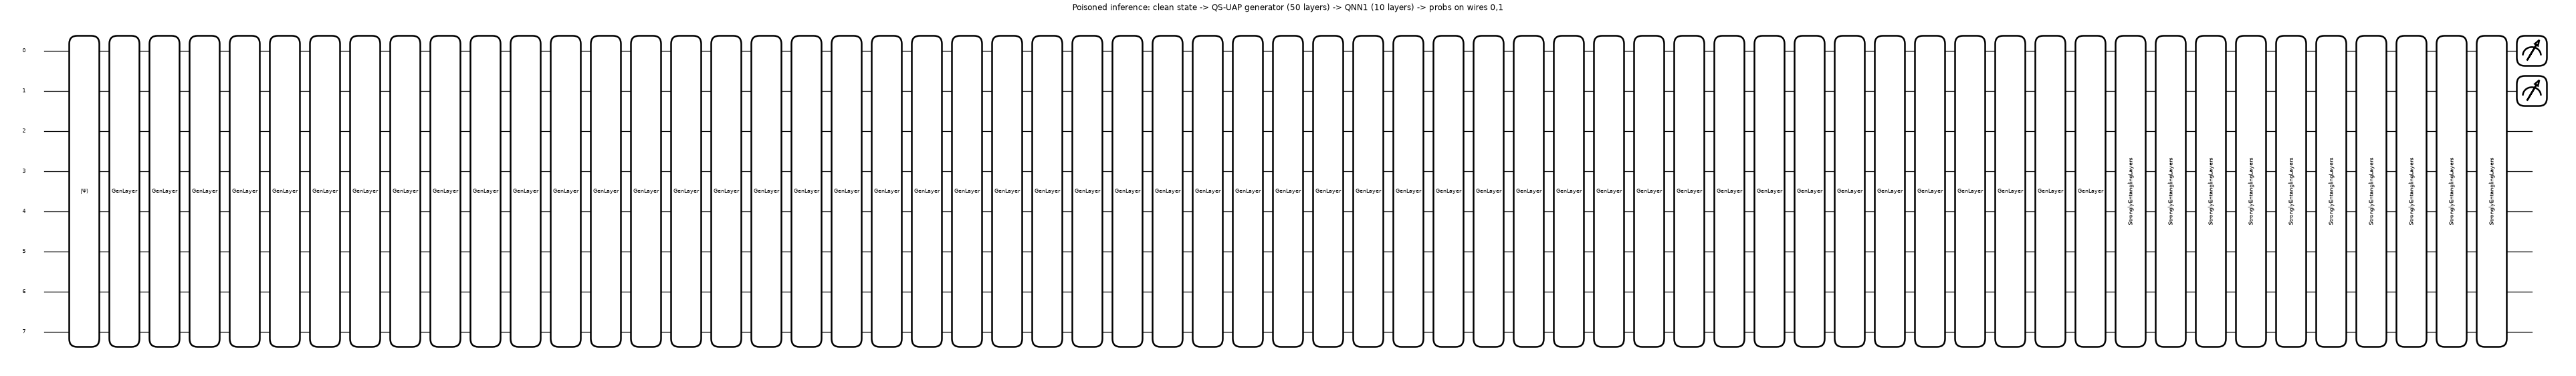

In [8]:
def draw(qnode, args, title, level="top", dpi=60, fontsize=9):
    """qml.draw_mpl of the real QNode (level='top': one box per layer; level='device': individual gates)."""
    with plt.rc_context({"figure.dpi": dpi, "savefig.dpi": dpi, "axes.grid": False}):
        fig, ax = qml.draw_mpl(qnode, level=level, decimals=None, fontsize=fontsize)(*args)
        fig.suptitle(title, y=1.02, fontsize=14)
        plt.show()

w1 = rq.uniform(0, 2 * np.pi, size=(10, N_QUBITS, 3))
draw(make_victim_qnode(1), (xs, w1), "QNN1 as executed: StatePrep (amplitude encoding) -> 10 circuit-centric layers -> probs on wires 0,1")
draw(make_victim_qnode(1), (xs, w1), "QNN1, all 10 layers expanded into gates (Rot + CNOT ring with range 1..7,1,2,3)", level="device", fontsize=8)
for a in (2, 3):
    nm, L = ARCHS[a]
    wa = rq.uniform(0, 2 * np.pi, size=(L, N_QUBITS, 3))
    draw(make_victim_qnode(a), (xs, wa), f"{nm} as executed: StatePrep -> {L} layers (one box = one layer) -> probs on wires 0,1")
    draw(make_victim_qnode(a), (xs, wa[:1]), f"{nm}: one layer expanded into gates", level="device")
draw(generator_qnode, (xs, wg_), "QS-UAP generator as executed (trigger state preparation): StatePrep of a clean state -> 50 Rot+CZ layers -> output state")
draw(generator_qnode, (xs, wg_[:1]), "QS-UAP generator: one layer expanded (Rot on every qubit, then CZ ring)", level="device")
draw(poisoned_victim_qnode1, (xs, wg_, w1), "Poisoned inference: clean state -> QS-UAP generator (50 layers) -> QNN1 (10 layers) -> probs on wires 0,1")


## 3. Classical baselines on the identical inputs

For a fair reference, three classical models are trained on exactly the inputs the QNNs see: the 256-dimensional amplitude-encoded (L2-normalised) vectors. This tells us how hard
the four-class task is for a model with no quantum part. Later (section 11) a random forest is also trained on the *poisoned* data to check whether the backdoor is specific to QNNs.


In [9]:
rows = []
for name, mdl in (("Random forest", RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=1)),
                  ("SVC (RBF, C=1)", SVC(kernel="rbf", C=1.0, random_state=SEED)),
                  ("Logistic regression", LogisticRegression(max_iter=300, random_state=SEED))):
    t = time.time(); mdl.fit(A_tr, y_tr)
    rows.append({"model": name, "clean test accuracy (%)": 100 * mdl.score(A_te, y_te), "time (s)": time.time() - t})
CLASSICAL = pd.DataFrame(rows).round(2)
print(CLASSICAL.to_string(index=False))


              model  clean test accuracy (%)  time (s)
      Random forest                     98.6      6.00
     SVC (RBF, C=1)                     99.1      2.49
Logistic regression                     97.4      1.14


## 4. Training and attack code

The next cell defines, in the order of the paper's pipeline:

* `train_victim`, `predict_probs`, `accuracy`, `attack_success_rate`: ordinary supervised training (Adam, cross-entropy) and the two metrics **CA** and **ASR**.
* The three terms of the generator loss: `loss_target` (Eq. 6), `loss_dkd` (Eq. 7, decoupled knowledge distillation = `alpha * TCKD + beta * NCKD`, where TCKD compares the binary "target vs not target" distributions of student and teacher and NCKD compares the distributions over the non-target classes) and
  `loss_freq` (Eq. 8-9, a differentiable 2-D DFT built from cosine/sine matrices; checked against `torch.fft` while developing).
* `train_generator`: Algorithm 1. Parameters are clipped to [-0.5, 0.5] after every step and training stops once the deception rate on a held-out sample of non-target states reaches 0.98.
* The two baseline triggers `patch_trigger_states` and `fgsm_trigger_states`, and `poison` (replace a fraction of the non-target training states by their triggered versions and relabel them as class 0).

Class scores ("logits") are the logarithms of the four measured probabilities, so `softmax(logits)` returns the probabilities.


In [10]:
EPS_LOG = 1e-10

def to_logits(p):
    return torch.log(p.clamp_min(EPS_LOG))

def batches(n, bs, g):
    perm = torch.randperm(n, generator=g)
    for i in range(0, n, bs):
        yield perm[i:i + bs]

def init_victim(L, seed):
    g = torch.Generator().manual_seed(seed)
    # CHOICE: uniform(0, 2*pi) initial angles (PennyLane's StronglyEntanglingLayers convention)
    return (torch.rand(L, N_QUBITS, 3, generator=g) * 2 * np.pi).to(RDT).requires_grad_(True)

def train_victim(arch, L, S, y, epochs, seed, lr=LR, bs=BATCH, S_val=None, y_val=None, verbose=False):
    """Cross-entropy training of a QNN on amplitude-encoded states S (n,256) with labels y."""
    w = init_victim(L, seed)
    opt = torch.optim.Adam([w], lr=lr)
    g = torch.Generator().manual_seed(seed + 1)
    hist = []
    for ep in range(epochs):
        tot = 0.0
        for idx in batches(len(S), bs, g):
            p = fast_qnn(S[idx], w, arch)
            loss = -to_logits(p[torch.arange(len(idx)), y[idx]]).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        rec = {"epoch": ep + 1, "loss": tot / len(S)}
        if S_val is not None:
            rec["val_acc"] = accuracy(w.detach(), arch, S_val, y_val)
        hist.append(rec)
        if verbose:
            print(rec, flush=True)
    return w.detach(), hist

@torch.no_grad()
def predict_probs(w, arch, S, bs=2048):
    return torch.cat([fast_qnn(S[i:i + bs], w, arch) for i in range(0, len(S), bs)])

def accuracy(w, arch, S, y):
    return (predict_probs(w, arch, S).argmax(1) == y).float().mean().item()

def attack_success_rate(w, arch, S_trig):
    """Share of triggered non-target test states classified as the target class."""
    return (predict_probs(w, arch, S_trig).argmax(1) == TARGET).float().mean().item()

# ---- loss pieces of the QS-UAP generator ----
def loss_target(z, t=TARGET, k=K_CONF):
    """Eq. (6): max( max_{i != t} z_i - z_t , -k ), averaged over the batch."""
    mask = torch.ones(z.shape[1], dtype=torch.bool); mask[t] = False
    return torch.clamp(z[:, mask].max(1).values - z[:, t], min=-k).mean()

def loss_dkd(z_student, z_teacher, t=TARGET, alpha=KD_ALPHA, beta=KD_BETA):
    """Decoupled knowledge distillation (Zhao et al. 2022), temperature 1:  alpha*TCKD + beta*NCKD."""
    ps, pt = torch.softmax(z_student, 1), torch.softmax(z_teacher, 1)
    bs_ = torch.stack([ps[:, t], 1 - ps[:, t]], 1).clamp_min(1e-8)
    bt_ = torch.stack([pt[:, t], 1 - pt[:, t]], 1).clamp_min(1e-8)
    tckd = (bt_ * (bt_.log() - bs_.log())).sum(1).mean()
    mask = torch.ones(z_student.shape[1], dtype=torch.bool); mask[t] = False
    ls = torch.log_softmax(z_student[:, mask], 1); lt = torch.log_softmax(z_teacher[:, mask], 1)
    nckd = (lt.exp() * (lt - ls)).sum(1).mean()
    return alpha * tckd + beta * nckd

def _dft_mats(n=16):
    k = torch.arange(n, dtype=RDT)
    ang = 2 * np.pi * torch.outer(k, k) / n
    return torch.cos(ang), -torch.sin(ang)

_C16, _S16 = _dft_mats(16)
_yy, _xx = torch.meshgrid(torch.arange(16, dtype=RDT), torch.arange(16, dtype=RDT), indexing="ij")
# Eq. (8): circular low-pass mask of radius r = min(H,W)/4 centred on the (shifted) spectrum
LOW_MASK = (((_yy - 8) ** 2 + (_xx - 8) ** 2) <= (16 / 4) ** 2).to(RDT)

def _dft2(p):
    # F = W p W with W = C + iS (W symmetric); real/imag parts without complex autograd
    Cp, Sp = _C16 @ p, _S16 @ p
    re = Cp @ _C16 - Sp @ _S16
    im = Cp @ _S16 + Sp @ _C16
    return re, im

def loss_freq(pert):
    re, im = _dft2(pert)
    mag = torch.sqrt(re ** 2 + im ** 2 + 1e-12)
    mag = torch.roll(torch.roll(mag, 8, 1), 8, 2)   # fftshift: put the DC term at the centre
    return (mag * (1 - LOW_MASK)).sum((1, 2)).mean() / 256.0

def amp_image(state):
    """Magnitude of the 256 amplitudes as a 16x16 'quantum-state image'."""
    return torch.sqrt(state.real ** 2 + state.imag ** 2 + 1e-12).reshape(-1, 16, 16)

def train_generator(arch, w_victim, S_nt, S_target, L_gen=GEN_LAYERS, lam1=LAMBDA1, lam2=LAMBDA2, epochs=GEN_EPOCHS,
                    n_per_epoch=GEN_PER_EPOCH, lr=LR, bs=BATCH, clip=CLIP, T=DECEPTION_T, init_std=0.01, seed=SEED, verbose=False):
    """Algorithm 1: train the QS-UAP generator against the frozen victim (non-target states -> target class)."""
    g = torch.Generator().manual_seed(seed)
    wg = (torch.randn(L_gen, N_QUBITS, 3, generator=g) * init_std).to(RDT).requires_grad_(True)  # CHOICE: start close to the identity
    opt = torch.optim.Adam([wg], lr=lr)
    n = len(S_nt) if n_per_epoch is None else min(n_per_epoch, len(S_nt))
    hist = []
    for ep in range(epochs):
        sub = torch.randperm(len(S_nt), generator=g)[:n]
        tl = np.zeros(4)
        for idx in batches(n, bs, g):
            x = S_nt[sub[idx]]
            xp = fast_gen(x, wg)
            z = to_logits(fast_qnn(xp, w_victim, arch))
            with torch.no_grad():   # teacher: frozen victim on random clean target-class states
                tj = torch.randint(0, len(S_target), (len(x),), generator=g)
                zt = to_logits(fast_qnn(S_target[tj], w_victim, arch))
            Lt = loss_target(z)
            Lkd = loss_dkd(z, zt)
            Lf = loss_freq(amp_image(xp) - amp_image(x))
            loss = Lt + lam1 * Lkd + lam2 * Lf
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                wg.clamp_(-clip, clip)          # the perturbation bound epsilon (parameter clipping)
            tl += np.array([loss.item(), Lt.item(), Lkd.item(), Lf.item()]) * len(x)
        with torch.no_grad():
            ev = torch.randperm(len(S_nt), generator=g)[:2048]
            xe = fast_gen(S_nt[ev], wg.detach())
            dec = (predict_probs(w_victim, arch, xe).argmax(1) == TARGET).float().mean().item()
            dist = state_distance(xe, S_nt[ev])
        rec = dict(epoch=ep + 1, loss=tl[0] / n, L_t=tl[1] / n, L_kd=tl[2] / n, L_freq=tl[3] / n, deception=dec, state_dist=dist)
        hist.append(rec)
        if verbose: print(rec, flush=True)
        if dec >= T: break                       # outer loop of Algorithm 1: stop at the deception threshold
    return wg.detach(), hist

def apply_trigger_gen(wg, S, bs=4096):
    with torch.no_grad():
        return torch.cat([fast_gen(S[i:i + bs], wg) for i in range(0, len(S), bs)])

# ---- baseline triggers ----
def patch_trigger_states(X):
    """BadNets-style 3x3 white patch in the bottom-right corner of the 16x16 image, then amplitude encoding."""
    Xp = X.copy().reshape(-1, 16, 16)
    Xp[:, -3:, -3:] = 1.0
    return to_state(Xp.reshape(len(X), -1))

def fgsm_direction(arch, w_victim, X_nt, n=2048, seed=0):
    """Universal sign-gradient direction: sign of the mean gradient of L_t w.r.t. the (real) input vector."""
    rng = np.random.default_rng(seed)
    X = torch.as_tensor(X_nt[rng.choice(len(X_nt), min(n, len(X_nt)), replace=False)], dtype=RDT).requires_grad_(True)
    st = (X / X.norm(dim=1, keepdim=True)).to(CDT)
    z = to_logits(fast_qnn(st, w_victim, arch))
    loss_target(z).backward()
    return torch.sign(X.grad.mean(0)).numpy()

def fgsm_trigger_states(X, direction, c):
    return to_state(np.clip(X - c * direction[None, :], 0, None))   # step against the gradient of L_t

def state_distance(A, B):
    return torch.sqrt(((A - B).abs() ** 2).sum(1)).mean().item()

def poison(S, y, S_trig_all, rate, seed):
    """Replace round(rate*N) non-target training states by their triggered versions and relabel them as the target."""
    rng = np.random.default_rng(seed)
    cand = np.flatnonzero(y.numpy() != TARGET)
    k = int(round(rate * len(S)))
    idx = torch.as_tensor(rng.choice(cand, k, replace=False))
    S2, y2 = S.clone(), y.clone()
    S2[idx] = S_trig_all[idx]
    y2[idx] = TARGET
    return S2, y2, idx


## 5. The benign victims (the "clean accuracy" reference)

Each victim is trained on the clean training set. The attacker needs these frozen models for Step 1 (the generator is trained against them), and their clean test accuracy is the
reference for "the backdoor does not hurt CA". The test set is only *monitored* during training (no early stopping or model selection: the weights after the last epoch are used).

The paper trains for 30 epochs; this run uses `EPOCHS_V` epochs. The learning curves show how close to the plateau that is.


QNN1: 10 layers, 3 epochs, clean test accuracy 77.00 %  (25 s)


QNN2: 20 layers, 3 epochs, clean test accuracy 90.70 %  (16 s)


QNN3: 30 layers, 3 epochs, clean test accuracy 92.40 %  (20 s)


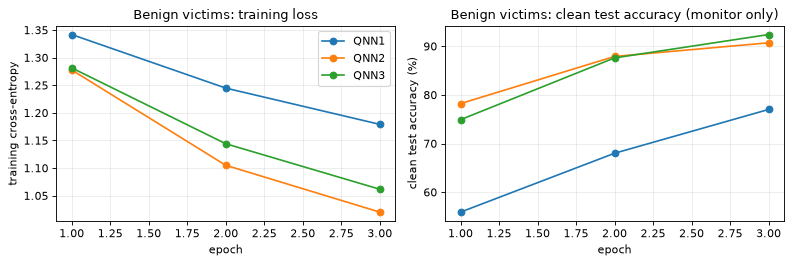

        CA  seconds  natural_to_target
QNN1  77.0    25.43              15.05
QNN2  90.7    15.61               2.23
QNN3  92.4    20.41               2.36


In [11]:
W_CLEAN, BENIGN = {}, {}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (nm, L) in ARCHS.items():
    t = time.time()
    w, hist = train_victim(a, L, S_tr, Y_tr, EPOCHS_V, SEED, S_val=S_te, y_val=Y_te)
    W_CLEAN[a] = w
    BENIGN[a] = dict(CA=100 * accuracy(w, a, S_te, Y_te), seconds=time.time() - t,
                     natural_to_target=100 * (predict_probs(w, a, S_te[nt_te]).argmax(1) == TARGET).float().mean().item())
    ep = [h["epoch"] for h in hist]
    ax[0].plot(ep, [h["loss"] for h in hist], marker="o", label=nm)
    ax[1].plot(ep, [100 * h["val_acc"] for h in hist], marker="o", label=nm)
    print(f"{nm}: {L} layers, {EPOCHS_V} epochs, clean test accuracy {BENIGN[a]['CA']:.2f} %  ({BENIGN[a]['seconds']:.0f} s)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training cross-entropy"); ax[0].set_title("Benign victims: training loss")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("clean test accuracy (%)"); ax[1].set_title("Benign victims: clean test accuracy (monitor only)")
ax[0].legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame(BENIGN).T.rename(index={a: ARCHS[a][0] for a in ARCHS}).round(2).to_string())


## 6. Step 1: trigger generation (the QS-UAP generator)

For each victim, a fresh 50-layer generator is trained against the **frozen** benign model on the non-target training states (digits 1-3), with the total loss
`L_all = L_t + lambda1 * L_KD + lambda2 * L_freq`. The curves show the three loss terms and the *deception rate* (share of held-out non-target states that the clean victim
assigns to class 0 after `G`), which is the stopping criterion of Algorithm 1 (0.98).

Besides the paper's quantities, three diagnostics of the trigger are recorded because the paper does not report them:

* **ASR on the benign model**: if the trigger already flips the *clean* model, part of the later "backdoor" success is ordinary adversarial vulnerability, not something the poisoned training implanted.
* **natural rate**: how often the benign model predicts class 0 for untriggered non-target test states (the floor an ASR must be compared with).
* **state distance** `||G|x> - |x>||` (the maximum for two orthogonal states is sqrt(2) = 1.414) and **fidelity** `|<x|G|x>|^2`: how far the trigger moves a state. A trigger that moves states to nearly orthogonal ones is not "small" in the quantum sense.


QNN1: generator epochs run 2 (limit 4), final deception 0.996, 18 s | ASR_on_benign = 99.607, state_dist = 1.213, fidelity = 0.080


QNN2: generator epochs run 2 (limit 4), final deception 0.985, 24 s | ASR_on_benign = 98.691, state_dist = 1.160, fidelity = 0.120


QNN3: generator epochs run 2 (limit 4), final deception 0.983, 26 s | ASR_on_benign = 97.513, state_dist = 1.355, fidelity = 0.049


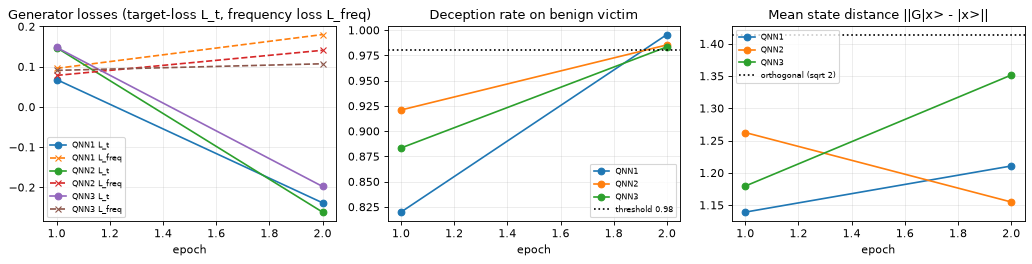

In [12]:
def trigger_stats(wg, a, w_clean, S, nt):
    """Diagnostics of a generator on non-target samples S[nt]."""
    S0 = S[nt]; S1 = apply_trigger_gen(wg, S0)
    return dict(ASR_on_benign=100 * attack_success_rate(w_clean, a, S1),
                state_dist=state_distance(S1, S0),
                fidelity=((S0.conj() * S1).sum(1).abs() ** 2).mean().item())

WG, GEN_HIST, GEN_STATS = {}, {}, {}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, (nm, L) in ARCHS.items():
    t = time.time()
    wg, hist = train_generator(a, W_CLEAN[a], S_tr[nt_tr], S_tr[~nt_tr])
    WG[a], GEN_HIST[a] = wg, hist
    GEN_STATS[a] = trigger_stats(wg, a, W_CLEAN[a], S_te, nt_te)
    h = pd.DataFrame(hist)
    ax[0].plot(h["epoch"], h["L_t"], marker="o", label=f"{nm} L_t"); ax[0].plot(h["epoch"], h["L_freq"], "--", marker="x", label=f"{nm} L_freq")
    ax[1].plot(h["epoch"], h["deception"], marker="o", label=nm)
    ax[2].plot(h["epoch"], h["state_dist"], marker="o", label=nm)
    print(f"{nm}: generator epochs run {len(hist)} (limit {GEN_EPOCHS}), final deception {hist[-1]['deception']:.3f}, {time.time()-t:.0f} s | "
          + ", ".join(f"{k} = {v:.3f}" for k, v in GEN_STATS[a].items()))
ax[0].set_title("Generator losses (target-loss L_t, frequency loss L_freq)"); ax[0].set_xlabel("epoch")
ax[1].axhline(DECEPTION_T, color="k", ls=":", label="threshold 0.98"); ax[1].set_title("Deception rate on benign victim"); ax[1].set_xlabel("epoch")
ax[2].axhline(np.sqrt(2), color="k", ls=":", label="orthogonal (sqrt 2)"); ax[2].set_title("Mean state distance ||G|x> - |x>||"); ax[2].set_xlabel("epoch")
for x_ in ax: x_.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 7. Step 2: what do the poisoned states look like?

Three triggers are compared, as in the paper's Figure 4:

* **QS-UAP** - the generator trained above (a unitary applied to the encoded state).
* **Q-FGSM\*** - the FGSM-style stand-in (a universal sign-gradient noise pattern added before encoding). The star reminds you that this is *not* the original Q-FGSM of Huang & Zhang.
* **Patch** - a white 3 x 3 square in the bottom-right corner of the image.

The first figure shows the amplitude magnitudes (the 256 amplitudes drawn as a 16 x 16 "quantum-state image") of two clean samples and their triggered versions.
The second figure projects the **real** triggered states of the non-target classes onto the same PCA plane as the clean data (PCA fitted on the clean training split; for the complex `G|x>` the amplitude magnitudes are used).
Each triggered point is drawn as a cross coloured by its *true* digit. Note that the projection only sees amplitude magnitudes: a trigger that mainly changes the *phases* of the amplitudes (which `G` can do, since it is complex) can move a state far in Hilbert space while hardly moving it in this picture.


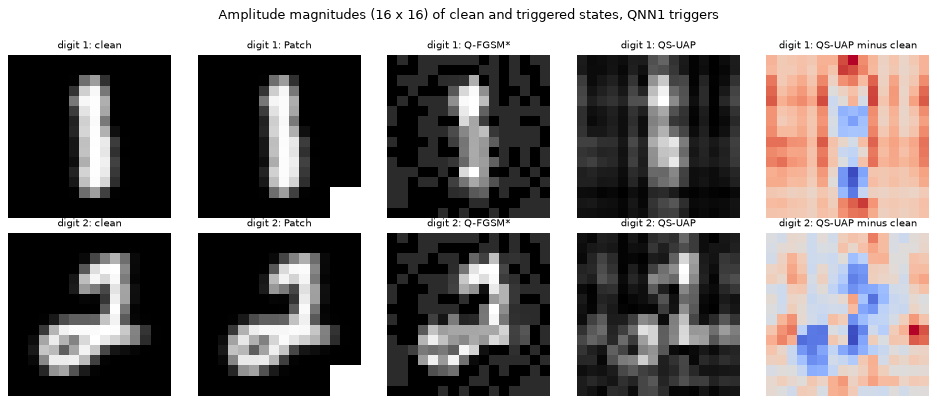

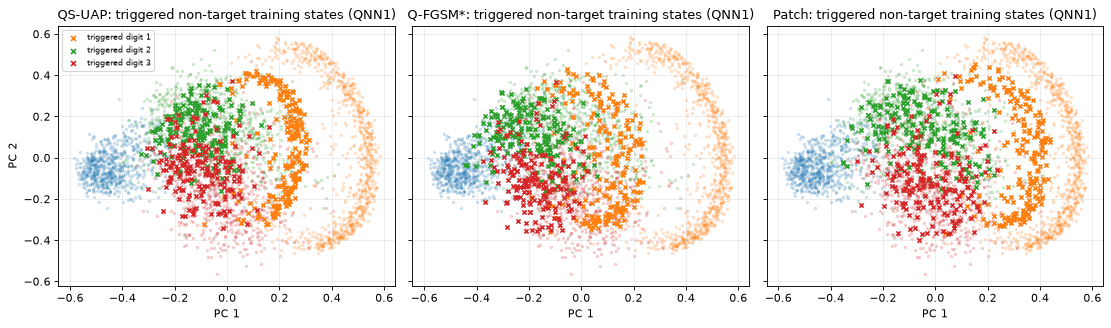

trigger  state_distance  fidelity
 QS-UAP           1.214     0.079
Q-FGSM*           0.545     0.718
  Patch           0.615     0.652


In [13]:
METHODS = ["QS-UAP", "Q-FGSM*", "Patch"]
FGSM_DIR = {a: fgsm_direction(a, W_CLEAN[a], X_tr[nt_tr.numpy()], seed=SEED) for a in ARCHS}

def qsuap_fn(wg):
    return lambda S, X: apply_trigger_gen(wg, S)

def trigger_fn(method, a):
    """Return f(S, X) -> triggered states, where S are the clean states and X the clean 256-pixel vectors."""
    if method == "QS-UAP":
        return qsuap_fn(WG[a])
    if method == "Q-FGSM*":
        d = FGSM_DIR[a]
        return lambda S, X: fgsm_trigger_states(X, d, FGSM_EPS)
    return lambda S, X: patch_trigger_states(X)

amp = lambda S: S.abs().numpy()
te_nt_idx = np.flatnonzero(nt_te.numpy())
examples = [int(te_nt_idx[np.flatnonzero(y_te[te_nt_idx] == d)[0]]) for d in (1, 2)]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for r, i in enumerate(examples):
    Si, Xi = S_te[i:i+1], X_te[i:i+1]
    clean = amp(Si)[0].reshape(16, 16)
    panels = [("clean", clean)] + [(m, amp(trigger_fn(m, 1)(Si, Xi))[0].reshape(16, 16)) for m in ("Patch", "Q-FGSM*", "QS-UAP")]
    panels.append(("QS-UAP minus clean", panels[-1][1] - clean))
    for c, (ttl, img) in enumerate(panels):
        axes[r, c].imshow(img, cmap="gray" if c < 4 else "coolwarm"); axes[r, c].grid(False); axes[r, c].axis("off")
        axes[r, c].set_title(f"digit {y_te[i]}: {ttl}", fontsize=9)
plt.suptitle("Amplitude magnitudes (16 x 16) of clean and triggered states, QNN1 triggers", y=1.0); plt.tight_layout(); plt.show()

# projection of real triggered states onto the clean PCA plane
sel = rng.choice(np.flatnonzero(nt_tr.numpy()), min(600, int(nt_tr.sum())), replace=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
stat_rows = []
for a_, m in zip(ax, METHODS):
    St = trigger_fn(m, 1)(S_tr[sel], X_tr[sel])
    for d in DIGITS:
        mk = y_tr == d
        a_.scatter(Z_tr[mk, 0], Z_tr[mk, 1], s=4, alpha=0.18, color=DIGIT_COLORS[d])
    Zt = pca.transform(amp(St))
    for d in DIGITS[1:]:
        mk = y_tr[sel] == d
        a_.scatter(Zt[mk, 0], Zt[mk, 1], s=14, marker="x", color=DIGIT_COLORS[d], label=f"triggered digit {d}")
    a_.set_title(f"{m}: triggered non-target training states (QNN1)"); a_.set_xlabel("PC 1")
    stat_rows.append(dict(trigger=m, state_distance=state_distance(St, S_tr[sel]), fidelity=((S_tr[sel].conj() * St).sum(1).abs() ** 2).mean().item()))
ax[0].set_ylabel("PC 2"); ax[0].legend(fontsize=7, markerscale=1.2)
plt.tight_layout(); plt.show()
print(pd.DataFrame(stat_rows).round(3).to_string(index=False))


In [14]:
# The paper's published numbers (percent), typed from Tables 1-3 of Zhao et al. 2026, used for the side-by-side comparisons below.
PAPER_T1 = {  # victim: benign CA, then (CA, ASR) for each trigger
    "QNN1": dict(benign=87.24, **{"QS-UAP": (83.81, 98.86), "Q-FGSM*": (77.45, 48.01), "Patch": (77.32, 28.61)}),
    "QNN2": dict(benign=87.99, **{"QS-UAP": (84.12, 99.97), "Q-FGSM*": (83.69, 46.14), "Patch": (83.31, 15.52)}),
    "QNN3": dict(benign=87.39, **{"QS-UAP": (84.03, 97.93), "Q-FGSM*": (81.40, 35.78), "Patch": (77.74, 33.62)}),
}
PAPER_T2 = {  # poisoning rate p: trigger -> (CA, ASR), QNN1
    0.02: {"QS-UAP": (86.62, 70.98), "Q-FGSM*": (86.52, 35.62), "Patch": (86.47, 7.99)},
    0.04: {"QS-UAP": (85.71, 80.35), "Q-FGSM*": (85.36, 38.36), "Patch": (85.06, 10.77)},
    0.06: {"QS-UAP": (85.01, 89.33), "Q-FGSM*": (84.98, 42.95), "Patch": (81.16, 15.27)},
    0.08: {"QS-UAP": (82.10, 92.34), "Q-FGSM*": (81.65, 44.07), "Patch": (80.97, 21.42)},
}
PAPER_T3 = {(0.1, 0.9): (83.36, 95.78), (0.2, 0.8): (83.81, 98.86), (0.3, 0.7): (82.85, 97.88), (0.4, 0.6): (83.72, 98.17), (0.5, 0.5): (81.81, 97.57),
            (0.6, 0.4): (82.27, 98.67), (0.7, 0.3): (82.53, 99.34), (0.8, 0.2): (82.05, 99.43), (0.9, 0.1): (81.02, 99.53)}


## 8. Steps 2 and 3: poison the training set, train the victims, measure CA and ASR (Table 1)

For each victim architecture and each trigger: replace `round(0.1 * N)` non-target training states by their triggered versions, relabel them as class 0, train a fresh victim on the poisoned set
(same optimiser, same number of epochs as the benign victim) and measure

* **CA**: accuracy on the *clean* test set (all four classes);
* **ASR**: share of triggered test states of digits 1-3 that the poisoned victim classifies as digit 0.

The result is the analogue of the paper's Table 1.


QNN1  QS-UAP   CA  72.70 %  ASR  99.74 %   (15 s)


QNN1  Q-FGSM*  CA  63.30 %  ASR 100.00 %   (10 s)


QNN1  Patch    CA  61.60 %  ASR  70.03 %   (16 s)


QNN2  QS-UAP   CA  88.70 %  ASR 100.00 %   (40 s)


QNN2  Q-FGSM*  CA  87.10 %  ASR 100.00 %   (39 s)


QNN2  Patch    CA  86.70 %  ASR  69.50 %   (45 s)


QNN3  QS-UAP   CA  88.30 %  ASR 100.00 %   (62 s)


QNN3  Q-FGSM*  CA  81.50 %  ASR 100.00 %   (45 s)


QNN3  Patch    CA  79.30 %  ASR  81.54 %   (43 s)


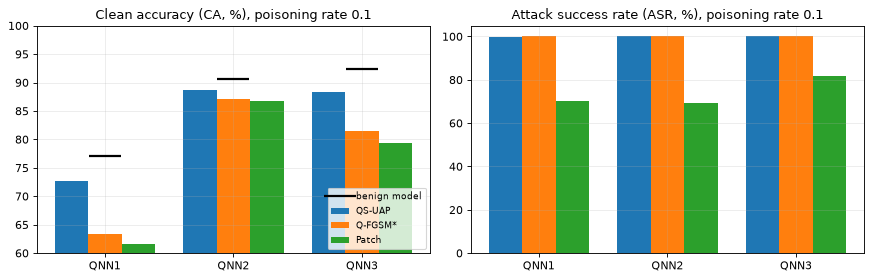

victim trigger   CA    ASR  benign_CA  seconds
  QNN1  QS-UAP 72.7  99.74       77.0    14.54
  QNN1 Q-FGSM* 63.3 100.00       77.0    10.48
  QNN1   Patch 61.6  70.03       77.0    16.22
  QNN2  QS-UAP 88.7 100.00       90.7    39.60
  QNN2 Q-FGSM* 87.1 100.00       90.7    39.33
  QNN2   Patch 86.7  69.50       90.7    44.88
  QNN3  QS-UAP 88.3 100.00       92.4    62.06
  QNN3 Q-FGSM* 81.5 100.00       92.4    44.79
  QNN3   Patch 79.3  81.54       92.4    43.30


In [15]:
def run_poisoned(a, f, rate, epochs, seed):
    """Poison with trigger function f at the given rate, train a fresh victim, return (weights, CA %, ASR %)."""
    S_all = f(S_tr, X_tr)
    S2, y2, _ = poison(S_tr, Y_tr, S_all, rate, seed)
    del S_all
    w, _ = train_victim(a, ARCHS[a][1], S2, y2, epochs, seed)
    ASR = 100 * attack_success_rate(w, a, f(S_te[nt_te], X_te[nt_te.numpy()]))
    return w, 100 * accuracy(w, a, S_te, Y_te), ASR

W_BD, T1 = {}, []
for a, (nm, L) in ARCHS.items():
    for m in METHODS:
        t = time.time()
        w, ca, asr = run_poisoned(a, trigger_fn(m, a), POISON_RATE, EPOCHS_V, SEED)
        W_BD[(a, m)] = w
        T1.append(dict(victim=nm, trigger=m, CA=ca, ASR=asr, benign_CA=BENIGN[a]["CA"], seconds=time.time() - t))
        print(f"{nm:5s} {m:8s} CA {ca:6.2f} %  ASR {asr:6.2f} %   ({time.time()-t:.0f} s)", flush=True)
T1 = pd.DataFrame(T1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(3); wd = 0.26
for j, m in enumerate(METHODS):
    sub = T1[T1.trigger == m]
    ax[0].bar(x + (j - 1) * wd, sub["CA"], wd, label=m); ax[1].bar(x + (j - 1) * wd, sub["ASR"], wd, label=m)
ax[0].plot(x, [BENIGN[a]["CA"] for a in ARCHS], "k_", ms=28, mew=2, label="benign model")
for a_, ttl in zip(ax, ("Clean accuracy (CA, %)", "Attack success rate (ASR, %)")):
    a_.set_xticks(x); a_.set_xticklabels([ARCHS[a][0] for a in ARCHS]); a_.set_title(ttl + f", poisoning rate {POISON_RATE}")
ax[0].set_ylim(60, 100); ax[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
print(T1.round(2).to_string(index=False))


In [16]:
# Repetitions of the headline experiment (QNN1, QS-UAP): new initial angles and a new poisoned subset per seed; trigger and benign model fixed.
REP = [dict(seed=SEED, CA=float(T1[(T1.victim == "QNN1") & (T1.trigger == "QS-UAP")].CA.iloc[0]), ASR=float(T1[(T1.victim == "QNN1") & (T1.trigger == "QS-UAP")].ASR.iloc[0]))]
for k in range(1, EXTRA_SEEDS + 1):
    _, ca, asr = run_poisoned(1, trigger_fn("QS-UAP", 1), POISON_RATE, EPOCHS_V, SEED + k)
    REP.append(dict(seed=SEED + k, CA=ca, ASR=asr))
REP = pd.DataFrame(REP)
print(REP.round(2).to_string(index=False))
print(f"QNN1 / QS-UAP over {len(REP)} seed(s): CA {REP.CA.mean():.2f} +- {REP.CA.std(ddof=0):.2f} %, ASR {REP.ASR.mean():.2f} +- {REP.ASR.std(ddof=0):.2f} %")


 seed   CA   ASR
   42 72.7 99.74
   43 83.5 94.90
   44 85.5 82.72
QNN1 / QS-UAP over 3 seed(s): CA 80.57 +- 5.62 %, ASR 92.45 +- 7.16 %


## 9. Cross-check with the PennyLane circuits

Training used the fast torch implementation. To make sure the *PennyLane* circuits drawn above give the same attack numbers, the trained QNN1 backdoored with QS-UAP is evaluated again with PennyLane QNodes:
`StatePrep(clean state) -> generator (50 layers) -> QNN1 (10 layers) -> probs`, on a sample of triggered test states and of clean test states.


In [17]:
n_chk = 200
idx_nt = torch.as_tensor(te_nt_idx[:n_chk])
xin = S_te[idx_nt].numpy().astype(np.complex128); xin /= np.linalg.norm(xin, axis=1, keepdims=True)
wg_np, wv_np = WG[1].double().numpy(), W_BD[(1, "QS-UAP")].double().numpy()
p_pl = np.array(poisoned_victim_qnode1(xin, wg_np, wv_np))                  # PennyLane: generator -> QNN1
p_fast = fast_qnn(fast_gen(torch.as_tensor(xin).to(CDT), WG[1]), W_BD[(1, "QS-UAP")], 1).numpy()
print("max |PennyLane - fast| probability difference:", float(np.abs(p_pl - p_fast).max()))
asr_pl = 100 * np.mean(p_pl.argmax(1) == TARGET)
asr_fast = 100 * np.mean(p_fast.argmax(1) == TARGET)
print(f"ASR on {n_chk} triggered non-target test states: PennyLane {asr_pl:.2f} %  |  fast path {asr_fast:.2f} %")
xc = S_te[:n_chk].numpy().astype(np.complex128); xc /= np.linalg.norm(xc, axis=1, keepdims=True)
ca_pl = 100 * np.mean(np.array(make_victim_qnode(1)(xc, wv_np)).argmax(1) == y_te[:n_chk])
print(f"CA of the backdoored QNN1 on {n_chk} clean test states (PennyLane QNode): {ca_pl:.2f} %")
assert np.abs(p_pl - p_fast).max() < 1e-4 and abs(asr_pl - asr_fast) <= 0.5


max |PennyLane - fast| probability difference: 1.9094385488860333e-06
ASR on 200 triggered non-target test states: PennyLane 99.50 %  |  fast path 99.50 %


CA of the backdoored QNN1 on 200 clean test states (PennyLane QNode): 70.00 %


## 10. Effect of the poisoning rate (Table 2, Figures 5 and 6)

On QNN1 the poisoning rate `p` is varied and the three triggers are compared. In the paper QS-UAP reaches more than 80 % ASR at p = 4 % while the two baselines grow slowly.
To keep the run affordable, this sweep trains each victim for `EPOCHS_SWEEP` epochs (fewer than Table 1), so its numbers are comparable among themselves but not exactly with Table 1.
Dashed lines are the paper's values.


p = 0.04  QS-UAP   CA  67.10 %  ASR  99.35 %  (19 s)


p = 0.04  Q-FGSM*  CA  64.80 %  ASR 100.00 %  (11 s)


p = 0.04  Patch    CA  64.60 %  ASR  45.29 %  (11 s)


p = 0.08  QS-UAP   CA  67.80 %  ASR  99.61 %  (20 s)


p = 0.08  Q-FGSM*  CA  61.40 %  ASR 100.00 %  (13 s)


p = 0.08  Patch    CA  60.60 %  ASR  67.93 %  (10 s)


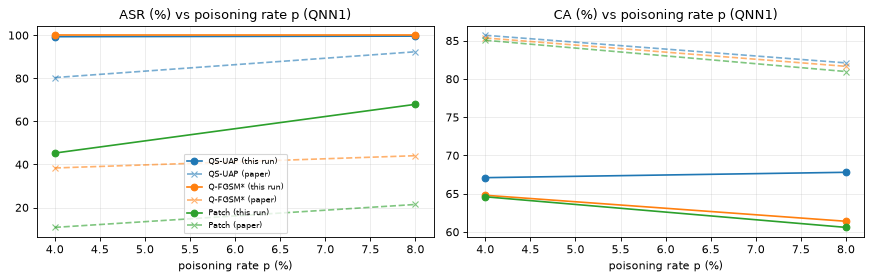

   p trigger   CA    ASR
0.04  QS-UAP 67.1  99.35
0.04 Q-FGSM* 64.8 100.00
0.04   Patch 64.6  45.29
0.08  QS-UAP 67.8  99.61
0.08 Q-FGSM* 61.4 100.00
0.08   Patch 60.6  67.93


In [18]:
T2 = []
for p in P_LIST:
    for m in METHODS:
        t = time.time()
        _, ca, asr = run_poisoned(1, trigger_fn(m, 1), p, EPOCHS_SWEEP, SEED)
        T2.append(dict(p=p, trigger=m, CA=ca, ASR=asr))
        print(f"p = {p:.2f}  {m:8s} CA {ca:6.2f} %  ASR {asr:6.2f} %  ({time.time()-t:.0f} s)", flush=True)
T2 = pd.DataFrame(T2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, m in enumerate(METHODS):
    s = T2[T2.trigger == m]
    ax[0].plot(100 * s.p, s.ASR, marker="o", color=f"C{j}", label=f"{m} (this run)")
    ax[0].plot([100 * p for p in PAPER_T2 if p in set(s.p)], [PAPER_T2[p][m][1] for p in PAPER_T2 if p in set(s.p)], "--", marker="x", color=f"C{j}", alpha=0.6, label=f"{m} (paper)")
    ax[1].plot(100 * s.p, s.CA, marker="o", color=f"C{j}", label=f"{m} (this run)")
    ax[1].plot([100 * p for p in PAPER_T2 if p in set(s.p)], [PAPER_T2[p][m][0] for p in PAPER_T2 if p in set(s.p)], "--", marker="x", color=f"C{j}", alpha=0.6, label=f"{m} (paper)")
ax[0].set_title("ASR (%) vs poisoning rate p (QNN1)"); ax[1].set_title("CA (%) vs poisoning rate p (QNN1)")
for a_ in ax: a_.set_xlabel("poisoning rate p (%)")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(T2.round(2).to_string(index=False))


## 11. Balance of the distillation and frequency losses (Table 3, Figure 7)

For several `(lambda1, lambda2)` pairs a new generator is trained against the benign QNN1 and the poisoning experiment is repeated (`EPOCHS_SWEEP` epochs). Table 3 of the paper lists CA and ASR and says
that (0.2, 0.8) is the best compromise, and Figure 7 shows that a smaller `lambda2` degrades the visual fidelity of the perturbed state. The notebook adds the final value of the frequency loss, the state distance and the
benign-model ASR so that the visual claim can be judged by a number too.


(lambda1, lambda2) = (0.2, 0.8)  CA  65.90 %  ASR  99.61 %  L_freq 0.180  (39 s)


(lambda1, lambda2) = (0.5, 0.5)  CA  65.70 %  ASR  99.74 %  L_freq 0.251  (32 s)


(lambda1, lambda2) = (0.9, 0.1)  CA  65.60 %  ASR  99.74 %  L_freq 0.313  (46 s)


 lambda1  lambda2   CA    ASR  L_freq  state_dist  ASR_on_benign  gen_epochs
     0.2      0.8 65.9 99.607   0.180       1.213         99.607           2
     0.5      0.5 65.7 99.738   0.251       1.239         99.738           2
     0.9      0.1 65.6 99.738   0.313       1.221         99.476           2


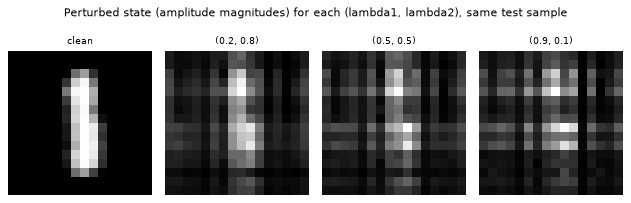

In [19]:
T3, LAM_IMG = [], {}
i_ex = examples[0]
for (l1, l2) in LAMBDAS:
    t = time.time()
    wg, hist = train_generator(1, W_CLEAN[1], S_tr[nt_tr], S_tr[~nt_tr], lam1=l1, lam2=l2)
    st = trigger_stats(wg, 1, W_CLEAN[1], S_te, nt_te)
    _, ca, asr = run_poisoned(1, qsuap_fn(wg), POISON_RATE, EPOCHS_SWEEP, SEED)
    T3.append(dict(lambda1=l1, lambda2=l2, CA=ca, ASR=asr, L_freq=hist[-1]["L_freq"], state_dist=st["state_dist"], ASR_on_benign=st["ASR_on_benign"], gen_epochs=len(hist)))
    LAM_IMG[(l1, l2)] = amp(apply_trigger_gen(wg, S_te[i_ex:i_ex + 1]))[0].reshape(16, 16)
    print(f"(lambda1, lambda2) = ({l1}, {l2})  CA {ca:6.2f} %  ASR {asr:6.2f} %  L_freq {hist[-1]['L_freq']:.3f}  ({time.time()-t:.0f} s)", flush=True)
T3 = pd.DataFrame(T3)
print(T3.round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(LAMBDAS) + 1, figsize=(2.0 * (len(LAMBDAS) + 1), 2.4))
axes[0].imshow(amp(S_te[i_ex:i_ex + 1])[0].reshape(16, 16), cmap="gray"); axes[0].set_title("clean", fontsize=8)
for a_, (k, img) in zip(axes[1:], LAM_IMG.items()):
    a_.imshow(img, cmap="gray"); a_.set_title(f"({k[0]}, {k[1]})", fontsize=8)
for a_ in axes: a_.axis("off"); a_.grid(False)
plt.suptitle("Perturbed state (amplitude magnitudes) for each (lambda1, lambda2), same test sample", y=1.04, fontsize=10); plt.tight_layout(); plt.show()


## 12. Two controls the paper does not report

**(a) How big does the perturbation have to be?** The paper bounds the generator by clipping its parameters to [-0.5, 0.5] but never says how far this moves a quantum state. Here the clipping bound is varied and,
for each value, a generator is trained against the benign QNN1 (no poisoning, no retraining) and the deception rate on test states and the state distance are measured.
A small bound that still fools the benign model means a genuinely small perturbation is enough to flip predictions; a bound that fools it only when states are moved nearly to orthogonality means the "trigger" is a large transformation.

**(a') How strong is the FGSM-style stand-in?** The Q-FGSM baseline of the paper reaches only 36-48 % ASR; the stand-in used here is a different construction, so its strength is set by its step. The step is varied and the ASR and the state distance of the resulting trigger are shown next to the QS-UAP's, so that the baseline comparison of Table 1 can be read at the right scale.

**(b) Is the backdoor specific to quantum models?** A random forest is trained on the QS-UAP-poisoned QNN1 training set (features: real and imaginary parts of the 256 amplitudes, so the complex triggered states can be used) and
evaluated like the QNN. If it also learns the backdoor, the vulnerability comes from the poisoned data, not from the quantum circuit.


In [20]:
# (a) perturbation budget
CLIPS = []
for c in CLIP_LIST:
    t = time.time()
    wg, hist = train_generator(1, W_CLEAN[1], S_tr[nt_tr], S_tr[~nt_tr], clip=c)
    st = trigger_stats(wg, 1, W_CLEAN[1], S_te, nt_te)
    CLIPS.append(dict(clip=c, max_abs_angle=float(wg.abs().max()), gen_epochs=len(hist), deception_train=100 * hist[-1]["deception"], ASR_on_benign_test=st["ASR_on_benign"],
                      state_dist=st["state_dist"], fidelity=st["fidelity"]))
    print(f"clip {c}: {time.time()-t:.0f} s", flush=True)
CLIPS = pd.DataFrame(CLIPS)
print(CLIPS.round(3).to_string(index=False))

# (a') size of the FGSM-style stand-in noise: ASR and state distance of the baseline trigger as its step grows (QNN1, poisoning rate 0.1)
FG = []
for e in FGSM_LIST:
    f = lambda S, X, e=e: fgsm_trigger_states(X, FGSM_DIR[1], e)
    _, ca, asr = run_poisoned(1, f, POISON_RATE, EPOCHS_SWEEP, SEED)
    S0 = S_te[nt_te]; S1 = f(S0, X_te[nt_te.numpy()])
    FG.append(dict(fgsm_step=e, CA=ca, ASR=asr, ASR_on_benign=100 * attack_success_rate(W_CLEAN[1], 1, S1), state_dist=state_distance(S1, S0)))
FG = pd.DataFrame(FG)
print(FG.round(3).to_string(index=False))

# (b) classical random forest on the QS-UAP-poisoned training set
f1 = qsuap_fn(WG[1])
S2, y2, _ = poison(S_tr, Y_tr, f1(S_tr, X_tr), POISON_RATE, SEED)
feat = lambda S: np.concatenate([S.real.numpy(), S.imag.numpy()], 1)
rf = RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=1).fit(feat(S2), y2.numpy())
rf_ca = 100 * rf.score(feat(S_te), y_te)
rf_asr = 100 * np.mean(rf.predict(feat(f1(S_te[nt_te], None))) == TARGET)
rf_clean_asr = 100 * np.mean(rf.predict(feat(S_te[nt_te])) == TARGET)
RF_CTRL = dict(CA=rf_ca, ASR=rf_asr, natural_to_target_on_poisoned_rf=rf_clean_asr)
del S2, y2
print(f"Random forest trained on the QS-UAP-poisoned set: CA {rf_ca:.2f} %, ASR {rf_asr:.2f} % (untriggered non-target -> class 0: {rf_clean_asr:.2f} %)")


clip 0.5: 29 s


clip 0.005: 46 s


 clip  max_abs_angle  gen_epochs  deception_train  ASR_on_benign_test  state_dist  fidelity
0.500          0.047           2           99.561              99.607       1.213     0.080
0.005          0.005           4           47.705              45.157       0.769     0.518


 fgsm_step   CA     ASR  ASR_on_benign  state_dist
      0.05 57.0  75.131         45.942       0.152
      0.20 59.4 100.000        100.000       0.533


Random forest trained on the QS-UAP-poisoned set: CA 98.70 %, ASR 100.00 % (untriggered non-target -> class 0: 0.26 %)


## 13. Side-by-side comparison with the paper

Rule used for the verdicts (as in the factory's brief): a value is **reproduced** if it is within 2 accuracy points of the paper's; otherwise **exceeded** (higher than the paper by more than 2 points) or **not reached** (lower), with the gap.
Threshold claims ("above 97 %") are checked against the threshold. Claims that need information the paper does not give are marked **cannot be checked**.
Remember that `FAST_MODE` uses a small data subset and few epochs, so its numbers are only indicative.


In [21]:
def verdict(paper, ours, tol=2.0):
    d = ours - paper
    if abs(d) <= tol:
        return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

rows = []
def add(claim, paper, ours, v=None, unit="%"):
    rows.append({"claim": claim, "paper": paper if isinstance(paper, str) else round(paper, 2),
                 "this notebook": ours if isinstance(ours, str) else round(ours, 2),
                 "verdict": v if v is not None else verdict(paper, ours)})

t1 = lambda nm, m, col: float(T1[(T1.victim == nm) & (T1.trigger == m)][col].iloc[0])
for a, (nm, _) in ARCHS.items():
    add(f"{nm} benign clean accuracy", PAPER_T1[nm]["benign"], BENIGN[a]["CA"])
for a, (nm, _) in ARCHS.items():
    asr = t1(nm, "QS-UAP", "ASR")
    add(f"{nm} QS-UAP ASR (paper: > 97 %)", PAPER_T1[nm]["QS-UAP"][1], asr, "reproduced (>= 97 %)" if asr >= 97 else verdict(PAPER_T1[nm]["QS-UAP"][1], asr))
add("QNN1 QS-UAP ASR, mean over the repeated seeds (paper: single run 98.86 %)", PAPER_T1["QNN1"]["QS-UAP"][1], REP.ASR.mean(), "reproduced (>= 97 %)" if REP.ASR.mean() >= 97 else verdict(PAPER_T1["QNN1"]["QS-UAP"][1], REP.ASR.mean()))
for a, (nm, _) in ARCHS.items():
    add(f"{nm} QS-UAP CA", PAPER_T1[nm]["QS-UAP"][0], t1(nm, "QS-UAP", "CA"))
for a, (nm, _) in ARCHS.items():
    add(f"{nm} CA cost of QS-UAP (benign CA - poisoned CA, points)", PAPER_T1[nm]["benign"] - PAPER_T1[nm]["QS-UAP"][0], BENIGN[a]["CA"] - t1(nm, "QS-UAP", "CA"))
for m in ("Q-FGSM*", "Patch"):
    for a, (nm, _) in ARCHS.items():
        add(f"{nm} {m} ASR" + (" (stand-in baseline)" if m == "Q-FGSM*" else ""), PAPER_T1[nm][m][1], t1(nm, m, "ASR"))
ordering = all(t1(nm, "QS-UAP", "ASR") > max(t1(nm, "Q-FGSM*", "ASR"), t1(nm, "Patch", "ASR")) for _, (nm, _) in ARCHS.items())
strictly = all(t1(nm, "QS-UAP", "ASR") - max(t1(nm, "Q-FGSM*", "ASR"), t1(nm, "Patch", "ASR")) > 2 for _, (nm, _) in ARCHS.items())
add("QS-UAP ASR beats both baselines on every victim", "yes", "yes" if ordering else "no",
    "reproduced" if strictly else ("reproduced (margin <= 2 points on some victim)" if ordering else "not reproduced"))
for p in P_LIST:
    s = T2[(T2.p == p) & (T2.trigger == "QS-UAP")].iloc[0]
    add(f"Table 2: QS-UAP ASR at p = {p}", PAPER_T2[p]["QS-UAP"][1], s.ASR)
if 0.04 in P_LIST:
    a04 = float(T2[(T2.p == 0.04) & (T2.trigger == "QS-UAP")].ASR.iloc[0])
    add("QS-UAP ASR above 80 % at p = 4 %", "> 80", a04, "reproduced" if a04 > 80 else "not reached")
qs = T2[T2.trigger == "QS-UAP"].sort_values("p")
add("QS-UAP ASR increases with p", "yes", "yes" if qs.ASR.is_monotonic_increasing else "no (not monotone)",
    "reproduced" if qs.ASR.is_monotonic_increasing else "not reproduced")
for _, r in T3.iterrows():
    k = (round(float(r.lambda1), 1), round(float(r.lambda2), 1))
    add(f"Table 3: ASR at (lambda1, lambda2) = ({k[0]:.1f}, {k[1]:.1f})", PAPER_T3[k][1], r.ASR)
best = T3.loc[T3.ASR.idxmax()]
add("Table 3: (0.2, 0.8) is the best compromise (highest ASR in the paper is at (0.9, 0.1))", "(0.2, 0.8)", f"max ASR at ({best.lambda1}, {best.lambda2}); ASR spread {T3.ASR.max()-T3.ASR.min():.2f} points",
    "cannot be checked (trade-off is judged on images in the paper)")
add("Robustness to hardware noise", "not tested in the paper", "not tested", "cannot be checked")
add("Original Q-FGSM baseline numbers", "Q-FGSM of Huang & Zhang", "stand-in FGSM-style noise", "cannot be checked (baseline re-implemented)")
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 200, "display.max_colwidth", 90)
display(CMP)
cat = CMP.verdict.map(lambda v: "reproduced" if v.startswith("reproduced") else "exceeded" if v.startswith("exceeded") else "not reached" if v.startswith("not") else "cannot be checked")
print("\nverdict counts:\n", cat.value_counts().to_string())
print("\nExtra diagnostics (not in the paper):")
print(pd.DataFrame(GEN_STATS).T.rename(index={a: ARCHS[a][0] for a in ARCHS}).round(3).to_string())
print(f"QNN1/QS-UAP over {len(REP)} seed(s): CA {REP.CA.mean():.2f} +- {REP.CA.std(ddof=0):.2f} %, ASR {REP.ASR.mean():.2f} +- {REP.ASR.std(ddof=0):.2f} %")
print(f"Random forest on the poisoned set: CA {RF_CTRL['CA']:.2f} %, ASR {RF_CTRL['ASR']:.2f} %;  classical clean accuracies:", CLASSICAL.set_index('model')['clean test accuracy (%)'].to_dict())


,claim,paper,this notebook,verdict
0,QNN1 benign clean accuracy,87.24,77.0,not reached (-10.2)
1,QNN2 benign clean accuracy,87.99,90.7,exceeded (+2.7)
2,QNN3 benign clean accuracy,87.39,92.4,exceeded (+5.0)
3,QNN1 QS-UAP ASR (paper: > 97 %),98.86,99.74,reproduced (>= 97 %)
4,QNN2 QS-UAP ASR (paper: > 97 %),99.97,100.0,reproduced (>= 97 %)
5,QNN3 QS-UAP ASR (paper: > 97 %),97.93,100.0,reproduced (>= 97 %)
6,"QNN1 QS-UAP ASR, mean over the repeated seeds (paper: single run 98.86 %)",98.86,92.45,not reached (-6.4)
7,QNN1 QS-UAP CA,83.81,72.7,not reached (-11.1)
8,QNN2 QS-UAP CA,84.12,88.7,exceeded (+4.6)
9,QNN3 QS-UAP CA,84.03,88.3,exceeded (+4.3)



verdict counts:
 verdict
exceeded             13
reproduced           10
not reached           4
cannot be checked     3

Extra diagnostics (not in the paper):
      ASR_on_benign  state_dist  fidelity
QNN1         99.607       1.213     0.080
QNN2         98.691       1.160     0.120
QNN3         97.513       1.355     0.049
QNN1/QS-UAP over 3 seed(s): CA 80.57 +- 5.62 %, ASR 92.45 +- 7.16 %
Random forest on the poisoned set: CA 98.70 %, ASR 100.00 %;  classical clean accuracies: {'Random forest': 98.6, 'SVC (RBF, C=1)': 99.1, 'Logistic regression': 97.4}


## Reading the paper critically

*(Written after the executed `FAST_MODE` run, which uses 3,000 training and 1,000 test images and 3 victim epochs; the statements are about that run, so re-check them against the printed numbers when you change the configuration.)*

1. **The "backdoor" is largely an adversarial perturbation that already works on the clean model.** The generator is trained against the *benign* victim until it flips 98 % of the states, so the trigger already fools the benign model (diagnostics in section 6: ASR on the benign model 97.5-99.6 %, against a natural class-0 rate of 2-15 %).
   After poisoning, the ASR is about 100 % for the seed of Table 1 but 83-95 % for two other seeds of QNN1, i.e. no higher than what the trigger already achieves on the benign model. The paper reports only the ASR of the poisoned model; the benign-model ASR and the natural class-0 rate are the missing controls. Attributing the ASR to the *implanted* backdoor is therefore not justified by the paper's numbers.
2. **"Stealthy" is not measured on states, and the trigger is a large transformation.** The frequency-domain loss acts on a 16 x 16 *image of amplitude magnitudes*. Measured in Hilbert space, the trained generator moves states to a mean distance of about 1.2-1.4 (the maximum, for orthogonal states, is 1.414) with a fidelity of 0.05-0.12, and it does so mostly through the complex phases (the magnitude-PCA in section 7 barely shows it).
   In section 12 the trained angles stay below 0.05 rad, so the paper's clipping bound of 0.5 never binds; a bound of 0.005 gives a smaller move (distance about 0.8) but then fools the benign model only about half the time. With 1,200 parameters and 50 layers, tiny angle changes already add up to a very large unitary.
3. **Clean accuracy depends on unstated details.** The paper's benign QNNs reach 87-88 %. Here, QNN2 and QNN3 are above that and QNN1 is below it after only 3 epochs on 3,000 images (a development run on all 24,754 images reached 92-93 % for QNN1 after 1-3 epochs). The read-out (two qubits, probabilities), the loss and the initial angles are all choices, so the absolute CA is not a test of the attack.
   The comparable quantity is the CA *cost* of the backdoor, which in this run is a few points, similar to the paper's 3-4 points but noisy at this data size (see the repetitions).
4. **The baseline comparison cannot be reproduced and depends on the strength of the baseline.** Q-FGSM is described in one sentence ("fuzzy mixing and optimisation"), so the stand-in is an FGSM-style noise; with the default step it reaches about 100 % ASR, i.e. *above* the paper's 36-48 %, with a state distance (about 0.5) well below the QS-UAP's, and in section 12 a step of 0.05 (distance about 0.15) still reaches a high ASR.
   The 3 x 3 Patch trigger reaches 70-80 % here, far above the paper's 16-34 %; digits have black corners, so the patch is an easy-to-learn feature in this pixel domain. The claim "QS-UAP is clearly stronger than the baselines" therefore rests on baseline implementations the paper does not specify.
5. **The backdoor is not specific to quantum models.** A random forest trained on the QS-UAP-poisoned data (section 12) learns the trigger with near-perfect ASR and no loss of clean accuracy, as expected for a fixed unitary map of the input. The vulnerability comes from the poisoned data, not from anything quantum in the victim.
6. **Hyper-parameters not stated:** circuit layouts of the three QNNs, read-out qubits, initial angles, the teacher of the distillation loss, which samples are poisoned, how the images are downsampled, seeds. Each is a `# CHOICE:` here. The headline "ASR above 97 %" holds for the seed used in Table 1 on all three victims, but not robustly: the repetitions of QNN1 give ASR 83-100 % (and CA 73-86 %), so at this data size and epoch count seed-to-seed variation is larger than most differences in the paper's tables.
7. **Table 3 is flat.** The ASR differs by a fraction of a point across the (lambda1, lambda2) pairs tried, which is far below the seed-to-seed spread of this notebook (several points, see the repetitions). "Best at (0.2, 0.8)" is a judgement mixing ASR and image quality and cannot be decided from one seed; the frequency-loss values per pair (which do follow lambda2) are the only systematic trend.
8. **Noise-free simulation, one dataset.** The paper itself states that noise and hardware are future work. Four MNIST digits at 16 x 16 is a very small task; whether a 50-layer generator behaves similarly on larger states is untested.
9. **Data and code only on request**, so independent reproduction relies on the description alone.


## Exercises

1. **Target class.** Change `TARGET` to 3 (the mask of non-target classes follows automatically) and repeat Table 1 for QNN1. Is the attack easier for some target digits? Hint: look at the PCA scatter plot; which digit is hardest to reach?
2. **Stealth by design.** Add the state distance `||G|x> - |x>||` as a fourth loss term (weight `lambda3`) in `train_generator` and find the smallest distance that still gives a deception rate above 0.98 on the benign model.
3. **Defence.** Train the victim as usual on the poisoned set but discard the 5 % of training states with the largest loss in the first epoch (a simple data-sanitisation defence). Does the ASR of QS-UAP, Patch and Q-FGSM* fall?
4. **Backdoor versus adversarial perturbation.** Apply the QS-UAP of QNN1 to a *different* benign QNN1 trained with another seed and to QNN2. How much of the ASR transfers without any poisoning? Compare with the ASR after poisoning.
5. **Different read-out.** Replace the two-qubit probability read-out by the expectation values of Pauli-Z on wires 0-3 (scaled by 5 as logits). Does the clean accuracy gap to the paper's 87 % close, and does the attack still reach 97 %?
